# 부산항 입항 패턴 · 총톤수/터미널별 재항시간 기초 분석

> **사용 자료:** `port_raw.xlsx` 파일의 **`매칭성공` 시트만** 사용  
> **목적:** 나중에 기상 데이터를 결합하기 전에, 평소 입항량과 선박별 재항시간의 기준선을 만든다.  
> **추천 분석 기간:** 2020~2024년 (2019년은 실제 입항 기준 29건뿐인 부분 자료)

## 처음 보는 사람을 위한 설명

- **입항 건수:** 배가 항만에 들어온 횟수. 같은 배가 여러 번 들어오면 각각 1건으로 계산한다.
- **재항시간:** `출항일시 - 입항일시`. 배가 부산항에 들어온 뒤 나갈 때까지 걸린 시간이며 **터미널 선석에 붙어 있었던 시간과 다르다.**
- **총톤수(GT):** 선박 내부 용적을 바탕으로 만든 크기 지표. 실제 선박 무게나 화물 중량이 아니다.
- **중앙값(50백분위수):** 재항시간을 짧은 순서로 정렬했을 때 중간 값. 아주 긴 체류 기록의 영향을 덜 받는다.
- **90백분위수(P90):** 10척 중 약 9척은 이 시간 이하로 머무른다는 뜻이다.

### 목차
1. 기초 설정 및 품질 점검
2. **평소 입항 패턴:** 연도·날짜·월·요일·시간대
3. **총톤수·터미널별 재항시간:** 크기별·터미널별·크기×터미널
4. **산점도 + Pearson·Spearman 상관분석** (총톤수·입항건수·작업량·터미널)
5. 핵심 결과와 날씨 결합을 위한 데이터 저장

> **주의:** 모든 분석은 `매칭성공`에 포함된 입항 기록만 대상으로 하며, 부산항 전체 선박을 대표한다고 단정하지 않는다. 날씨의 영향은 아직 판단하지 않는다.

## 0. 설정: 엑셀 파일 읽기

- 기본은 2020~2024년, 모든 선박 종류를 포함한다.
- 풀컨테이너선만 보고 싶으면 `FULL_CONTAINER_ONLY = True`로 변경한다.
- 연도는 `입항연도` 열 대신 **실제 `입항일시`의 연도**를 기준으로 만든다.
- 코드는 원본 엑셀을 수정하지 않는다. 하단의 CSV/PNG만 새 폴더에 생성한다.

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import Markdown, display

# ===== 사용자 수정 설정 =====
START_YEAR, END_YEAR = 2020, 2024
FULL_CONTAINER_ONLY = False  # True: 풀컨테이너선만
SIZE_STEP_GT = 10_000
MIN_SIZE_GROUP_N = 100
MIN_HEATMAP_CELL_N = 30
# ==========================

# ===== 프로젝트 경로 설정 =====
def find_project_root(start=None):
    here = Path(start or Path.cwd()).resolve()

    for d in (here, *here.parents):
        if (
            (d / "pyproject.toml").is_file()
            and (d / "1.Rawdata_EDA").is_dir()
        ):
            return d

    raise FileNotFoundError(
        f"프로젝트 루트를 찾을 수 없습니다. 실행 위치: {here}"
    )


PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "1.Rawdata_EDA" / "Data"
DATA_PATH = DATA_DIR / "port_raw.xlsx"
FILE_PATH = DATA_PATH
SHEET_NAME = "매칭성공"

OUTPUT_DIR = (
    PROJECT_ROOT
    / "1.Rawdata_EDA"
    / "Output"
    / "부산항_기초분석_산출물"
)

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"엑셀 파일이 없습니다: {DATA_PATH}")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("읽는 파일:", DATA_PATH)
print("산출물 폴더:", OUTPUT_DIR)
# ==============================

# ===== 한글 글꼴 설정 =====
available_fonts = {
    f.name for f in font_manager.fontManager.ttflist
}

selected_font = next(
    (
        name
        for name in (
            "Malgun Gothic",
            "NanumSquare",
            "NanumGothic",
            "AppleGothic",
            "Noto Sans CJK KR",
        )
        if name in available_fonts
    ),
    None,
)

if selected_font is None:
    raise RuntimeError(
        "한글 글꼴을 찾지 못했습니다. "
        "맑은 고딕 또는 나눔고딕 설치 후 커널을 재시작하세요."
    )

plt.rcParams.update({
    "font.family": selected_font,
    "font.sans-serif": [selected_font],
    "axes.unicode_minus": False,
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110,
    "savefig.dpi": 160,
})

print("사용 폰트:", selected_font)

BLUE = "#245A81"
SKY = "#81B6D6"
TEAL = "#078A83"
ORANGE = "#D58D38"
GREY = "#707D8A"


def save_show(name, fig):
    fig.savefig(
        OUTPUT_DIR / f"{name}.png",
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)


def fmt_count(v, pos=None):
    return f"{v:,.0f}"


# ===== 원본 데이터 불러오기 =====
raw = pd.read_excel(FILE_PATH, sheet_name=SHEET_NAME)

need = [
    "입항일시",
    "출항일시",
    "총톤수",
    "터미널",
    "선박종류명",
]
miss = [c for c in need if c not in raw.columns]

if miss:
    raise ValueError(f"시트에 필수 열이 없습니다: {miss}")

raw["입항_dt"] = pd.to_datetime(
    raw["입항일시"], errors="coerce"
)
raw["출항_dt"] = pd.to_datetime(
    raw["출항일시"], errors="coerce"
)
raw["총톤수_GT"] = pd.to_numeric(
    raw["총톤수"], errors="coerce"
)
raw["재항시간_h"] = (
    raw["출항_dt"] - raw["입항_dt"]
).dt.total_seconds() / 3600
raw["실제_입항연도"] = raw["입항_dt"].dt.year

mask = raw["실제_입항연도"].between(
    START_YEAR, END_YEAR
)

if FULL_CONTAINER_ONLY:
    mask &= raw["선박종류명"].eq("풀컨테이너선")

df = raw.loc[mask].copy()

# 입항량 집계에 사용할 날짜 정보
df = df.loc[df["입항_dt"].notna()].copy()
df["입항일"] = df["입항_dt"].dt.normalize()
df["입항연도"] = df["입항_dt"].dt.year.astype(int)
df["입항월"] = df["입항_dt"].dt.month.astype(int)
df["요일번호"] = df["입항_dt"].dt.day_of_week

WEEKDAYS = ["월", "화", "수", "목", "금", "토", "일"]

# 입항·출항일시가 모두 있고 재항시간이 10분 초과인 자료
valid_dwell = (
    df["입항_dt"].notna()
    & df["출항_dt"].notna()
    & df["재항시간_h"].gt(10 / 60)
)
valid_dwell &= (
    df["총톤수_GT"].gt(0)
    & df["터미널"].notna()
)

dw = df.loc[valid_dwell].copy()

dw["크기_10k_gt"] = (
    np.floor(dw["총톤수_GT"] / SIZE_STEP_GT)
    * SIZE_STEP_GT
).astype(int)

dw["크기_라벨"] = dw["크기_10k_gt"].map(
    lambda s: (
        f"{s / 10000:g}~"
        f"{(s + SIZE_STEP_GT) / 10000:g}만GT"
    )
)

# 관측기간 모든 날짜 포함: 입항 기록이 없는 날짜는 0건
all_days = pd.date_range(
    f"{START_YEAR}-01-01",
    f"{END_YEAR}-12-31",
    freq="D",
)

daily = (
    df.groupby("입항일")
    .size()
    .reindex(all_days, fill_value=0)
    .rename("입항건수")
    .to_frame()
)

daily.index.name = "날짜"
daily["연도"] = daily.index.year
daily["월"] = daily.index.month
daily["요일번호"] = daily.index.day_of_week

daily["7일_이동평균"] = (
    daily.groupby("연도")["입항건수"]
    .transform(
        lambda s: s.rolling(
            7, min_periods=1
        ).mean()
    )
)

# ===== 데이터 상태 확인 =====
n_bad_dwell = len(df) - len(dw)

print(
    f"원본 매칭성공: {len(raw):,}건 / "
    f"기간·선종 적용 후: {len(df):,}건"
)
print(
    f"재항시간 비교 가능: {len(dw):,}건 / "
    f"시간·톤수·터미널 조건 미충족: "
    f"{n_bad_dwell:,}건"
)

print("입항일 기준 연도별 건수:")
display(
    df["입항연도"]
    .value_counts()
    .sort_index()
    .rename("건수")
    .to_frame()
    .T
)

print(
    "관측기간 날짜별 입항 건수 (0건 날짜 포함):",
    len(daily),
    "일",
)
print(
    "원본 총톤수 범위:",
    f"{dw['총톤수_GT'].min():,.0f}",
    "~",
    f"{dw['총톤수_GT'].max():,.0f}",
    "GT",
)

읽는 파일: C:\work\Port_Cast_Final\1.Rawdata_EDA\Data\port_raw.xlsx
산출물 폴더: C:\work\Port_Cast_Final\1.Rawdata_EDA\Output\부산항_기초분석_산출물
사용 폰트: Malgun Gothic
원본 매칭성공: 36,844건 / 기간·선종 적용 후: 36,815건
재항시간 비교 가능: 36,815건 / 시간·톤수·터미널 조건 미충족: 0건
입항일 기준 연도별 건수:


입항연도,2020,2021,2022,2023,2024
건수,7076,6455,6860,8275,8149


관측기간 날짜별 입항 건수 (0건 날짜 포함): 1827 일
원본 총톤수 범위: 1,864 ~ 236,583 GT


### 데이터 품질 해석

1. **왜 2019년을 제외했을까?** 2019년의 기록이 극히 적어서 1년 전체와 비교하면 오해할 수 있기 때문이다.
2. **왜 0건 날짜를 만들까?** 입항 기록이 없는 날짜를 아예 지우면 일평균을 과대평가할 수 있기 때문이다. 단, 실제로 배가 0척인지 단순히 `매칭성공` 자료가 없는 날인지는 확인이 필요하다.
3. **왜 재항시간에 상한선을 일괄 적용하지 않을까?** 긴 체류가 분석의 중요한 결과일 수 있어서이다. 음수·비정상적 시간 순서는 제외하되, 오래 머문 경우는 원본을 보존한다.
4. **터미널 시간과 다르다:** 여기의 `재항시간_h`는 부산항 입항과 출항 시각으로 계산하며, `터미널_접안시간`을 쓰지 않는다.

# 1. 평소 입항 패턴 — 원래 언제 많고 적은가?

## 그래프 1. 연도별 하루 평균 입항 건수

**어떻게 읽나요?** 막대가 높을수록 해당 연도에 하루 평균 입항한 선박 수가 많다. 연도별 총건수를 단순 비교하면 윤년(366일)과 평년(365일)의 영향을 받을 수 있어 **하루 평균**으로 비교한다. 막대 위에는 `하루 평균 / 연간 총건수`를 함께 표시했다.

**날씨 결합 전 의의:** 원래 연도마다 입항량이 달랐다면 날씨만으로 그 차이를 설명하면 안 된다.

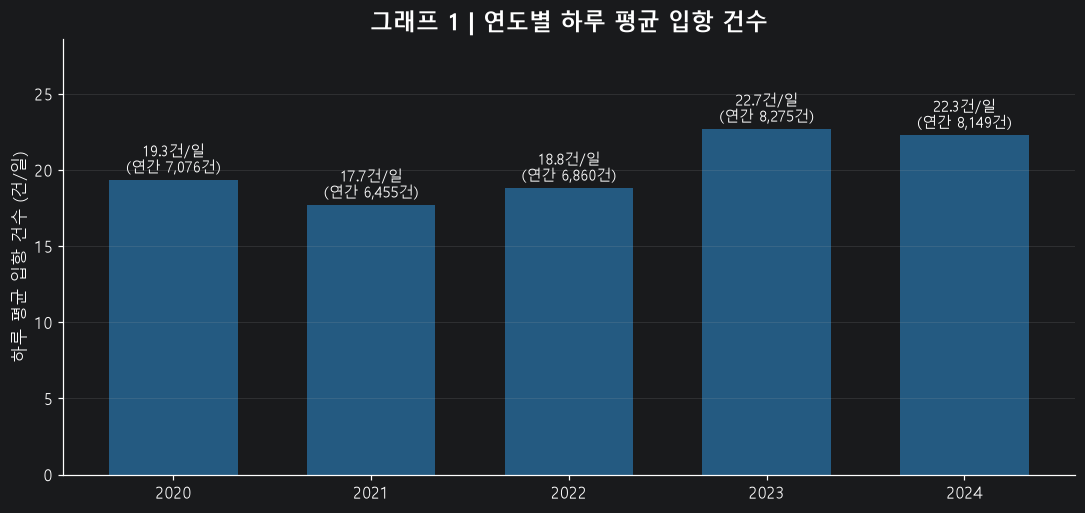

**데이터에서 읽기:** 하루 평균 입항 건수가 가장 많은 해는 **2023년(22.7건/일)**, 가장 적은 해는 **2021년(17.7건/일)**입니다. 이는 `매칭성공` 자료 기준 결과입니다.

In [5]:
year_daily = daily.groupby('연도')['입항건수'].agg(['mean','sum','median']).rename(
    columns={'mean':'하루평균','sum':'연간건수','median':'하루중앙값'})
fig, ax = plt.subplots(figsize=(10,4.8))
xs = np.arange(len(year_daily))
bars = ax.bar(xs, year_daily['하루평균'], color=BLUE, width=.65)
ax.set_xticks(xs, year_daily.index.astype(str))
ax.set_ylabel('하루 평균 입항 건수 (건/일)')
ax.set_title('그래프 1 | 연도별 하루 평균 입항 건수')
ax.set_ylim(0,year_daily['하루평균'].max()*1.26)
for bar, (_, row) in zip(bars, year_daily.iterrows()):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+.3,
            f"{row['하루평균']:.1f}건/일\n(연간 {row['연간건수']:,.0f}건)",
            ha='center',va='bottom',fontsize=10)
ax.grid(axis='y', alpha=.19)
fig.tight_layout(); save_show('01_연도별_하루평균',fig)
lo=year_daily['하루평균'].idxmin(); hi=year_daily['하루평균'].idxmax()
display(Markdown(f"**데이터에서 읽기:** 하루 평균 입항 건수가 가장 많은 해는 **{hi}년({year_daily.loc[hi,'하루평균']:.1f}건/일)**, 가장 적은 해는 **{lo}년({year_daily.loc[lo,'하루평균']:.1f}건/일)**입니다. 이는 `매칭성공` 자료 기준 결과입니다."))

## 그래프 2. 일일 입항 건수와 7일 이동평균

**연한 선:** 날짜마다 실제로 집계된 입항 건수. **짙은 선:** 최근 7일을 평균 내어 급격한 하루 변화가 조금 완화된 선.

- 하루만 튀는 봉우리와 며칠 이어지는 높은 구간을 구분할 수 있다.
- 여기서는 날씨와 관계없이 관측된 전체 패턴이다.
- 7일 이동평균은 매년 1월에 초기화했다. **급증 판정 기준 자체는 아니다.**

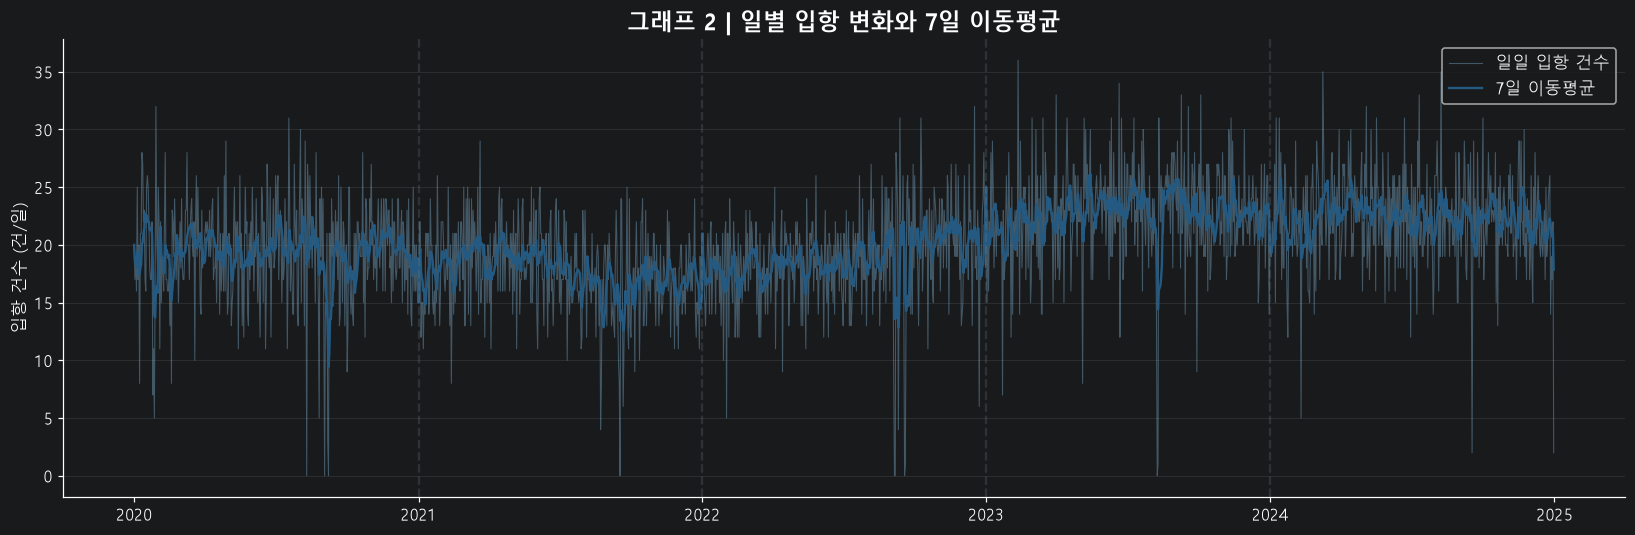

입항 건수 일별 중앙값 20건, 90백분위수 26건, 최대 36건


In [6]:
fig, ax = plt.subplots(figsize=(15,5.0))
ax.plot(daily.index, daily['입항건수'], color=SKY, linewidth=.7, alpha=.4, label='일일 입항 건수')
ax.plot(daily.index, daily['7일_이동평균'], color=BLUE, linewidth=1.55,label='7일 이동평균')
for yr in range(START_YEAR+1,END_YEAR+1):
    ax.axvline(pd.Timestamp(f'{yr}-01-01'), linestyle='--', color=GREY,alpha=.25)
ax.set_ylabel('입항 건수 (건/일)')
ax.set_title('그래프 2 | 일별 입항 변화와 7일 이동평균')
ax.legend(loc='upper right'); ax.grid(axis='y',alpha=.17)
fig.tight_layout(); save_show('02_일별_입항과_7일이동평균',fig)
print(f"입항 건수 일별 중앙값 {daily['입항건수'].median():.0f}건, 90백분위수 {daily['입항건수'].quantile(.90):.0f}건, 최대 {daily['입항건수'].max():.0f}건")

## 그래프 3. 월별 '하루 평균' 입항 건수 — 해마다 비슷한가?

가로축은 1~12월, 각 선은 하나의 연도이다. **월마다 날짜 수가 다르므로 해당 월의 총건수를 월 일수로 나누어** 비교한다.

선들이 매년 비슷한 달에 함께 높다면 계절적 패턴 가능성을 생각할 수 있다. 한 해에만 튀었다면 그 해의 다른 사건이나 자료 범위를 먼저 확인해야 한다.

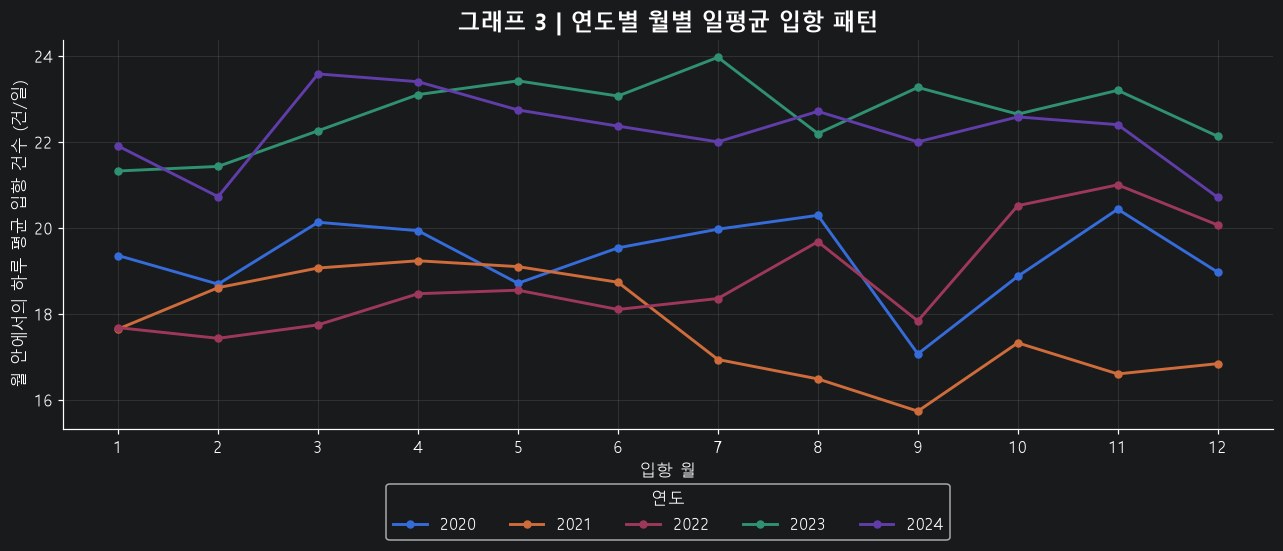

**전체 5년 평균:** 하루 평균 입항이 상대적으로 많은 달은 **4월(20.8건/일)**, 적은 달은 **9월(19.2건/일)**입니다. 실제 차이는 각 연도 선과 함께 해석하세요.

In [7]:
monthly = daily.groupby(['연도','월'])['입항건수'].agg(['sum','mean','median','count']).reset_index()
m_piv = monthly.pivot(index='월',columns='연도',values='mean')
fig,ax=plt.subplots(figsize=(11.8,5.2))
for yr in m_piv.columns:
    ax.plot(m_piv.index, m_piv[yr],marker='o',linewidth=1.9,markersize=4.5,label=str(yr))
ax.set_xticks(range(1,13)); ax.set_xlabel('입항 월')
ax.set_ylabel('월 안에서의 하루 평균 입항 건수 (건/일)')
ax.set_title('그래프 3 | 연도별 월별 일평균 입항 패턴')
ax.legend(title='연도',ncol=5,loc='upper center',bbox_to_anchor=(.5,-.12))
ax.grid(alpha=.2)
fig.tight_layout(); save_show('03_연도별_월별_입항패턴',fig)
month_avg=daily.groupby('월')['입항건수'].mean()
display(Markdown(f"**전체 5년 평균:** 하루 평균 입항이 상대적으로 많은 달은 **{month_avg.idxmax()}월({month_avg.max():.1f}건/일)**, 적은 달은 **{month_avg.idxmin()}월({month_avg.min():.1f}건/일)**입니다. 실제 차이는 각 연도 선과 함께 해석하세요."))

## 그래프 4. 연도 × 월의 입항 수준 히트맵

표의 각 칸은 그 연도·그 달의 **하루 평균 입항 건수**이다. 진할수록 입항이 많다. 월별 선그래프와 같은 데이터를 표처럼 보여주므로, 특정 연도의 특별히 높은 달 또는 낮은 달을 찾기 좋다.

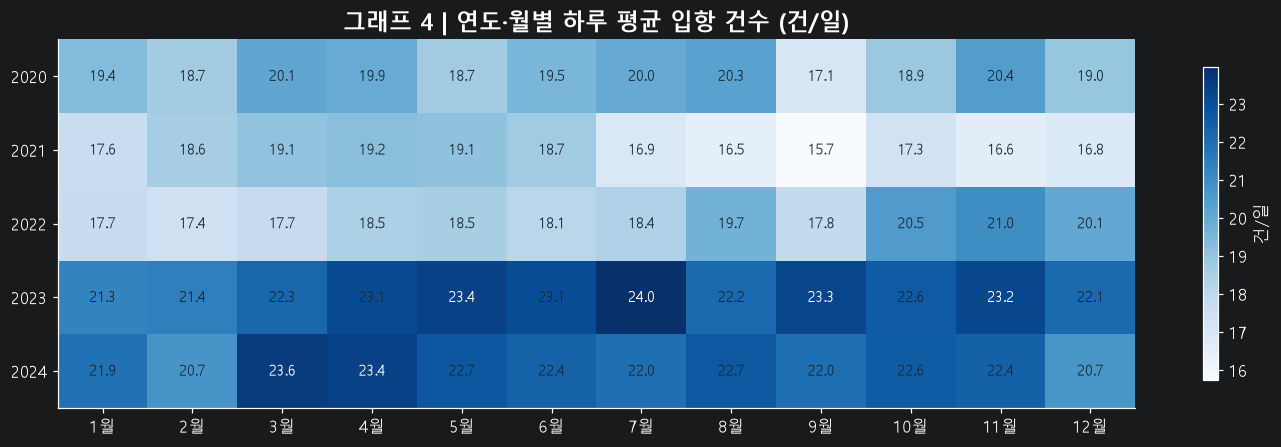

In [8]:
table = monthly.pivot(index='연도',columns='월',values='mean')
fig,ax=plt.subplots(figsize=(13,4.2))
im=ax.imshow(table.values,aspect='auto',cmap='Blues')
ax.set_xticks(np.arange(12),[f'{i}월' for i in range(1,13)])
ax.set_yticks(np.arange(len(table)),table.index.astype(str))
ax.set_title('그래프 4 | 연도·월별 하루 평균 입항 건수 (건/일)')
cut=np.nanmean(table.values)
for r in range(table.shape[0]):
    for c in range(table.shape[1]):
        v=table.iloc[r,c]
        ax.text(c,r,f'{v:.1f}',ha='center',va='center',fontsize=10,
                color=('white' if v>cut*1.15 else '#1C2A37'))
cbar=fig.colorbar(im,ax=ax,shrink=.85); cbar.set_label('건/일')
fig.tight_layout(); save_show('04_연도월_입항_히트맵',fig)

## 그래프 5. 요일별 하루 입항 건수 분포

상자그림은 단순히 평균 하나만 보여주는 것과 달리 **날마다 얼마나 들쭉날쭉한지** 보여준다.

- 상자 안 **가운데 선**은 중앙값(평범한 수준).
- 상자 높이는 가운데 50%의 날짜가 모여 있는 범위이다.
- 아래·위 수염은 극단적인 날을 제외한 분포의 범위를 보여준다.

**주의:** 공휴일 여부는 아직 구분하지 않았고, 주말도 제외하지 않았다. 이것은 나중에 날씨 분석을 할 때 평소 요일 차이를 조정하기 위한 자료이다.

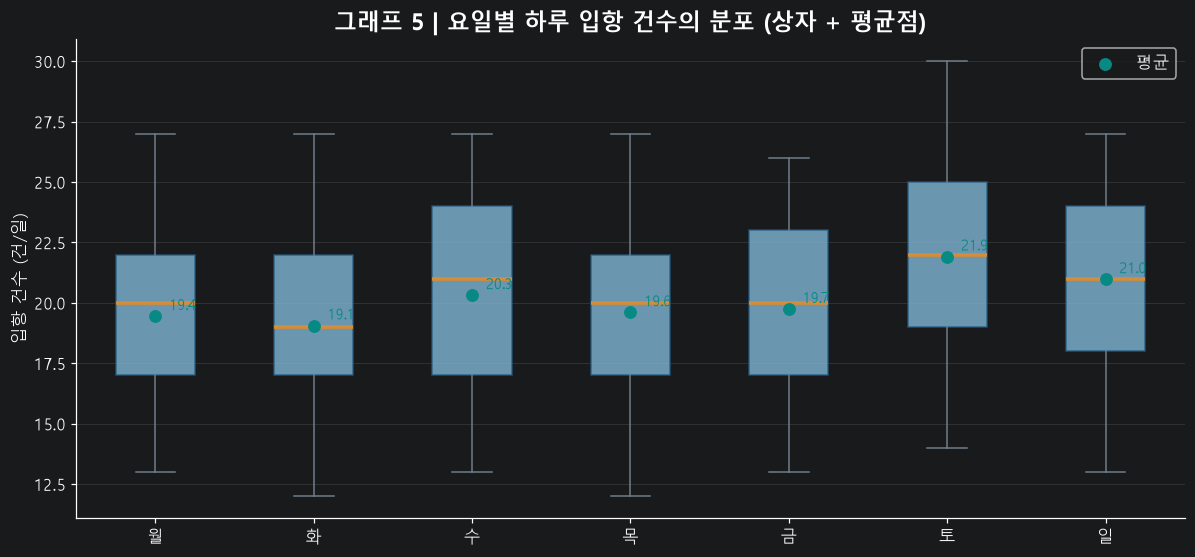

**데이터에서 읽기:** 요일별 평균은 **토요일(21.9건/일)**이 가장 높고 **화요일(19.1건/일)**이 가장 낮습니다. 평균 차이가 날씨 때문이라는 뜻은 아닙니다.

In [9]:
week_data=[daily.loc[daily['요일번호']==i,'입항건수'].values for i in range(7)]
fig,ax=plt.subplots(figsize=(11,5.2))
bp=ax.boxplot(week_data,patch_artist=True,showfliers=False,whis=(5,95))
for b in bp['boxes']: b.set(facecolor=SKY,edgecolor=BLUE,alpha=.8)
for m in bp['medians']: m.set(color=ORANGE,linewidth=2.4)
for w in bp['whiskers']+bp['caps']: w.set(color=GREY)
means=[np.mean(x) for x in week_data]
ax.scatter(range(1,8),means,color=TEAL,zorder=5,label='평균',s=55)
for i,val in enumerate(means,1):
    ax.annotate(f'{val:.1f}',(i,val),xytext=(9,4),textcoords='offset points',color=TEAL,fontsize=10)
ax.set_xticks(range(1,8),WEEKDAYS)
ax.set_ylabel('입항 건수 (건/일)')
ax.set_title('그래프 5 | 요일별 하루 입항 건수의 분포 (상자 + 평균점)')
ax.legend(); ax.grid(axis='y',alpha=.2)
fig.tight_layout(); save_show('05_요일별_입항건수_상자그림',fig)
wd=pd.Series(means,index=WEEKDAYS)
display(Markdown(f"**데이터에서 읽기:** 요일별 평균은 **{wd.idxmax()}요일({wd.max():.1f}건/일)**이 가장 높고 **{wd.idxmin()}요일({wd.min():.1f}건/일)**이 가장 낮습니다. 평균 차이가 날씨 때문이라는 뜻은 아닙니다."))

## 그래프 6. 요일 × 시간대: 보통 몇 시에 입항이 많은가?

세로축은 요일, 가로축은 0~23시이다. 칸 안의 값은 **해당 요일에 해당 시간대의 평균 입항 건수(건/시간대·일)**이다. 해당 요일이 몇 번 있었는지로 나누었으므로 요일별 관측 일수 차이를 고려했다.

**날씨 결합 시 의의:** 예를 들어 새벽에 원래 입항이 적다면, 어떤 악천후 날 새벽 입항이 적었다는 사실만으로 기상 영향을 주장할 수 없다.

In [10]:
df['입항시간대'] = df['입항_dt'].dt.hour

In [11]:
df[['입항_dt', '요일번호', '입항시간대']].head()

,입항_dt,요일번호,입항시간대
0,2020-01-22 12:00:00,2,12
1,2020-01-21 03:10:00,1,3
2,2020-01-19 14:00:00,6,14
3,2020-01-19 22:00:00,6,22
4,2020-01-20 15:00:00,0,15


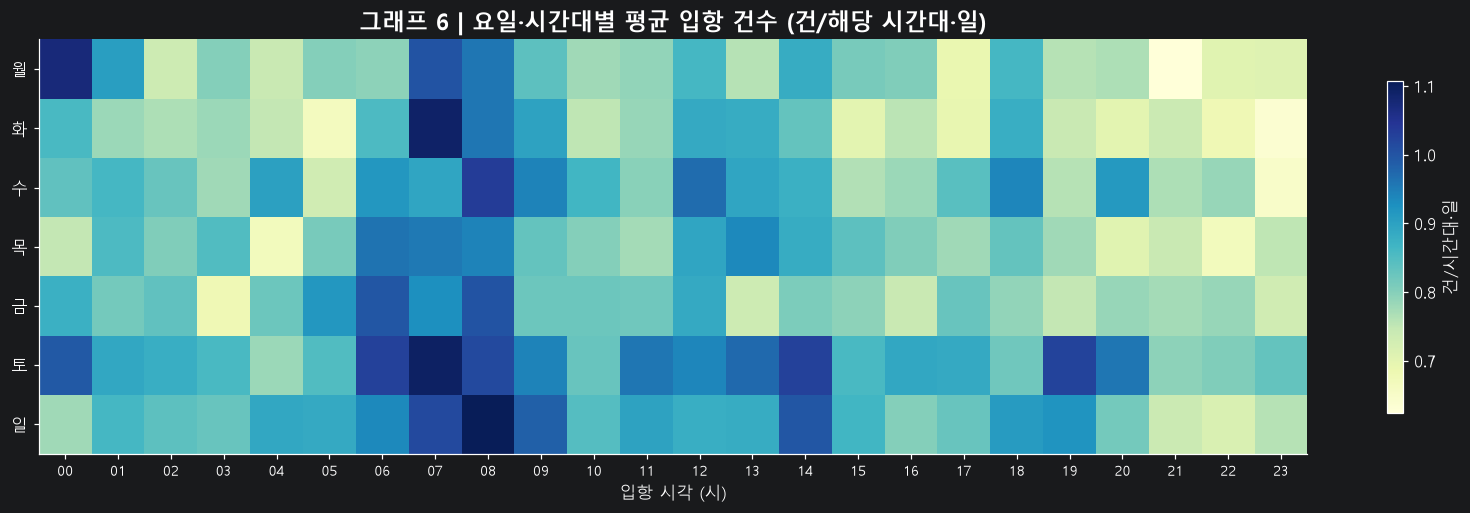

**데이터에서 읽기:** 가장 높은 칸은 **일요일 08시대, 평균 1.11건/일**입니다. 이 값은 해당 시간대에 속한 1시간 평균 건수입니다.

In [12]:
hour_counts=df.groupby(['요일번호','입항시간대']).size().unstack(fill_value=0).reindex(index=range(7),columns=range(24),fill_value=0)
weekday_denominators=daily.groupby('요일번호').size().reindex(range(7))
hour_perday=hour_counts.div(weekday_denominators,axis=0)
fig,ax=plt.subplots(figsize=(15,4.8))
im=ax.imshow(hour_perday.values,aspect='auto',cmap='YlGnBu')
ax.set_yticks(range(7),WEEKDAYS)
ax.set_xticks(range(24),[f'{h:02d}' for h in range(24)],fontsize=9)
ax.set_xlabel('입항 시각 (시)')
ax.set_title('그래프 6 | 요일·시간대별 평균 입항 건수 (건/해당 시간대·일)')
fig.colorbar(im,ax=ax,label='건/시간대·일',shrink=.8)
fig.tight_layout(); save_show('06_요일시간대_입항_히트맵',fig)
i,j=np.unravel_index(np.nanargmax(hour_perday.values),hour_perday.shape)
display(Markdown(f"**데이터에서 읽기:** 가장 높은 칸은 **{WEEKDAYS[i]}요일 {j:02d}시대, 평균 {hour_perday.iloc[i,j]:.2f}건/일**입니다. 이 값은 해당 시간대에 속한 1시간 평균 건수입니다."))

# 2. 선박 크기·터미널별 재항시간 — 어떤 배가 오래 머무는가?

재항시간은 출항일시와 입항일시의 차이를 **시간(h)**으로 계산한다. 앞서 입항 패턴에 포함된 기록 중 시각·총톤수·터미널이 유효하고 재항시간이 10분보다 긴 기록을 이용한다.

**긴 재항시간은 유지한다.** 상자그림에서 극단값 점을 숨기거나 표시 범위를 제한하더라도 **통계 계산에서 자동 삭제하지 않는다.** 나중에 날씨 때문에 며칠씩 머문 사례를 찾기 위해서이다.

## 그래프 7. 총톤수 구간별 재항시간 — 중앙값과 90백분위수

총톤수는 **10,000GT 단위**로 구분한다. 아래 선 그래프는 해당 크기 배들이 보통 얼마나 오래 머무는지(중앙값)와 장시간 체류가 어느 정도인지(90백분위수) 보여준다. 아래 막대는 그 구간의 **입항 건수**이다.

입항 수가 거의 없는 크기 구간은 통계가 흔들리기 쉬우므로 `MIN_SIZE_GROUP_N` 이상인 구간만 그림에 표시한다. 빠진 구간은 0건이라는 뜻이 아니라 **표본이 적어 그래프에서 제외**한 것이다.

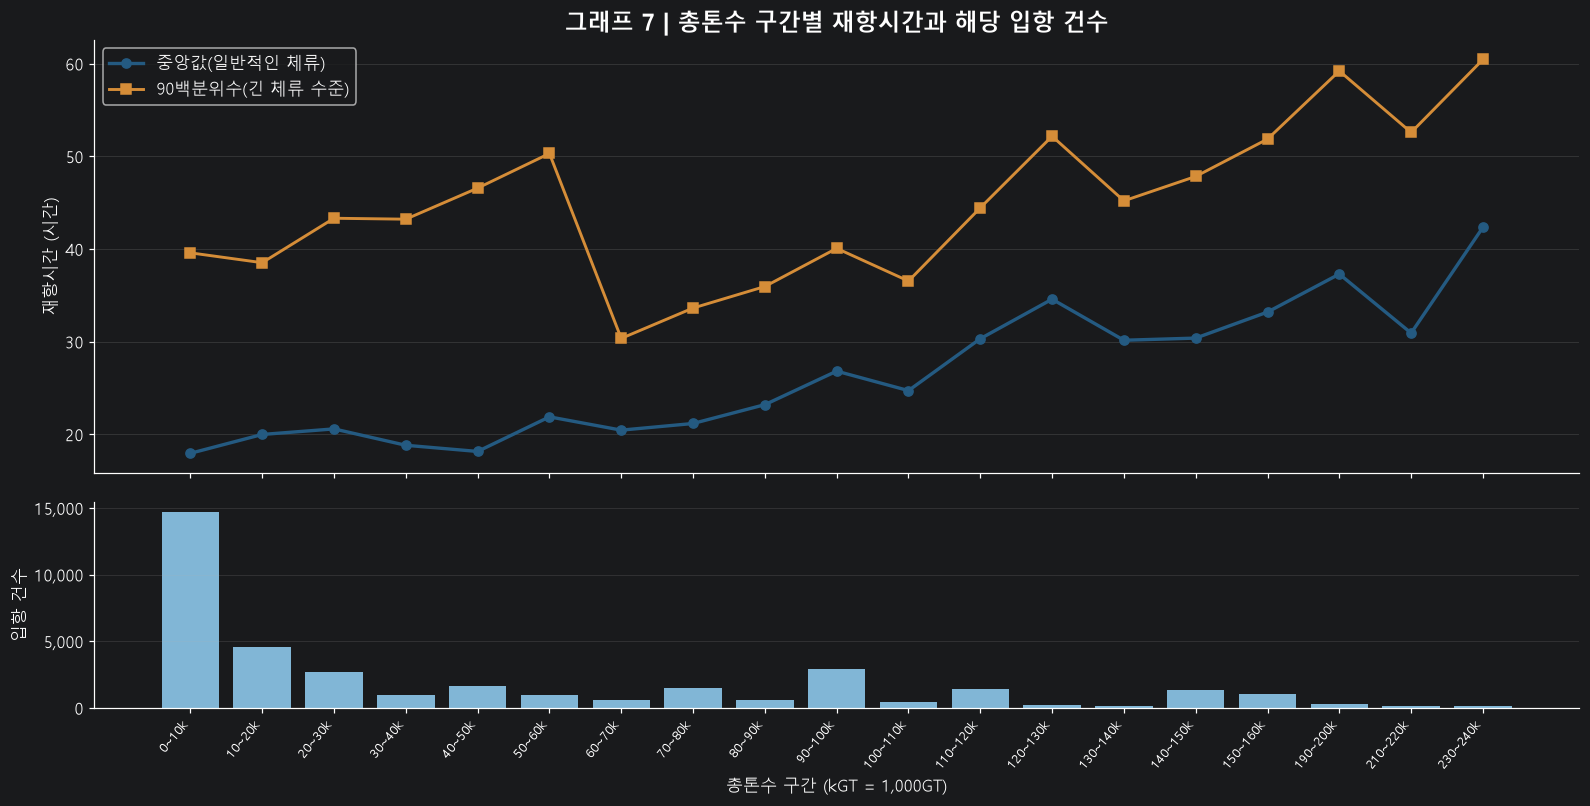

**그래프 대상 크기 구간:** 전체 23개 중 **19개**, 각 구간에 최소 100건 이상인 그룹만 표시했습니다. 구간 경계는 10,000GT 간격입니다.

In [13]:
sizes=dw.groupby('크기_10k_gt')['재항시간_h'].agg(
    n='size',med='median',mean='mean',p90=lambda x:x.quantile(.9)).sort_index()
sizes['표시'] = sizes.index.map(lambda s:f'{s//1000}~{(s+SIZE_STEP_GT)//1000}k')
sizes_plot=sizes.loc[sizes['n']>=MIN_SIZE_GROUP_N].copy()
fig,(ax1,ax2)=plt.subplots(2,1,figsize=(15,8.1),sharex=True,
                         gridspec_kw={'height_ratios':[2.1,1], 'hspace':.09})
ix=np.arange(len(sizes_plot))
ax1.plot(ix,sizes_plot['med'],color=BLUE,linewidth=2.2,marker='o',label='중앙값(일반적인 체류)')
ax1.plot(ix,sizes_plot['p90'],color=ORANGE,linewidth=1.9,marker='s',label='90백분위수(긴 체류 수준)')
ax1.set_title('그래프 7 | 총톤수 구간별 재항시간과 해당 입항 건수')
ax1.set_ylabel('재항시간 (시간)'); ax1.legend(loc='upper left')
ax1.grid(axis='y',alpha=.22)
ax2.bar(ix,sizes_plot['n'],color=SKY)
ax2.set_ylabel('입항 건수');ax2.set_xlabel('총톤수 구간 (kGT = 1,000GT)')
ax2.set_xticks(ix,sizes_plot['표시'],rotation=50,ha='right',fontsize=8.5)
ax2.yaxis.set_major_formatter(FuncFormatter(fmt_count));ax2.grid(axis='y',alpha=.2)
fig.subplots_adjust(left=.08, right=.98, bottom=.17, top=.92, hspace=.08); save_show('07_총톤수_재항시간_중앙값_P90',fig)
valid_groups=len(sizes_plot)
display(Markdown(f"**그래프 대상 크기 구간:** 전체 {len(sizes)}개 중 **{valid_groups}개**, 각 구간에 최소 {MIN_SIZE_GROUP_N}건 이상인 그룹만 표시했습니다. 구간 경계는 10,000GT 간격입니다."))

## 그래프 8. 선박 크기별 재항시간 분포 — 상자그림

같은 크기의 배라도 모두 같은 시간에 출항하는 것은 아니다. 아래 상자그림은 차이의 크기를 보여준다.

- 상자 가운데 선 = 중앙값.
- 수염 = 대체로 가운데 90%를 아우르는 5~95백분위 영역.
- 보기 편하도록 **90시간보다 높은 부분은 그래프 화면에서만 자르지만 원본 데이터와 통계는 그대로 유지**한다.

이 그림만으로 큰 배가 오래 머무는 ‘이유’를 판단할 수는 없다. 큰 배는 작업량이 더 많거나 들어오는 터미널이 다를 수 있기 때문이다.

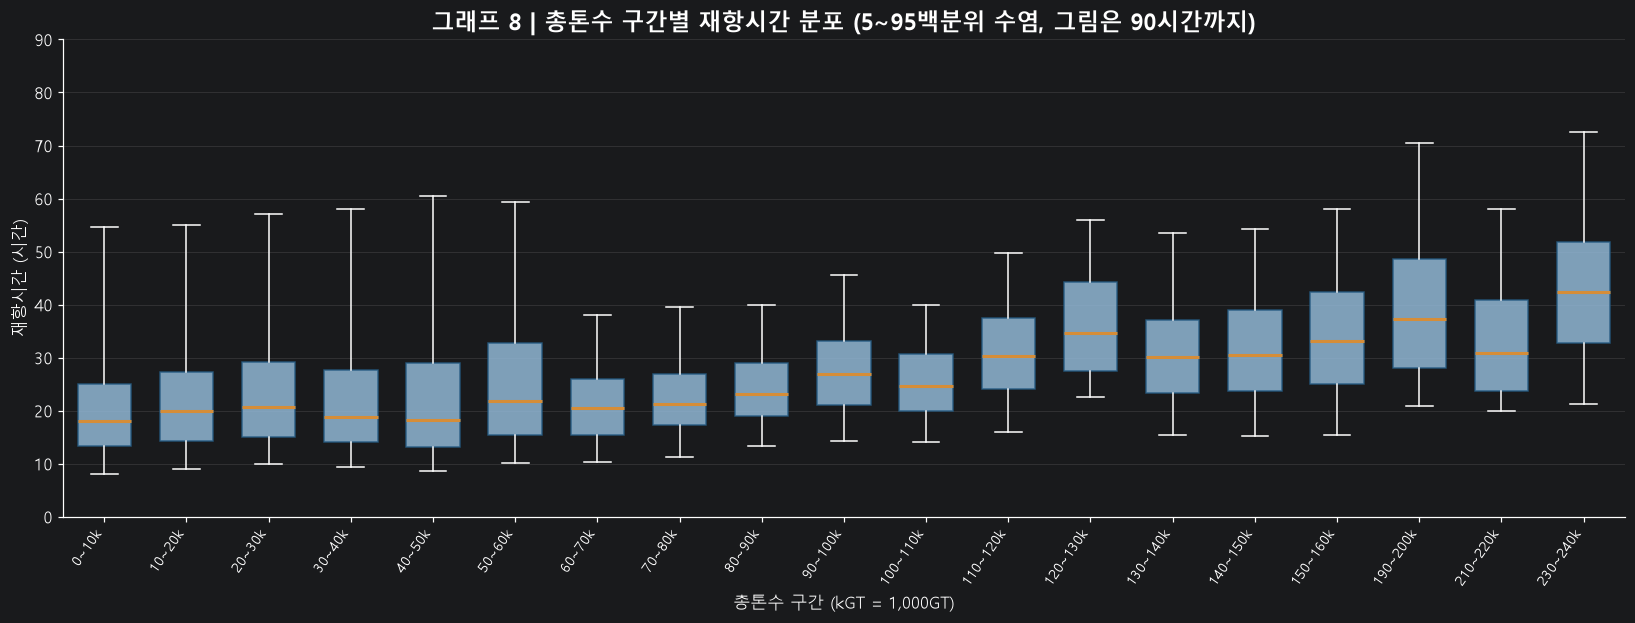

In [14]:
grp_keys=sizes_plot.index.tolist()
box_data=[dw.loc[dw['크기_10k_gt']==g,'재항시간_h'].values for g in grp_keys]
fig,ax=plt.subplots(figsize=(15,5.8))
bp=ax.boxplot(box_data,showfliers=False,whis=(5,95),patch_artist=True, widths=.65)
for b in bp['boxes']:b.set(facecolor='#91B7D5',edgecolor=BLUE,alpha=.85)
for m in bp['medians']:m.set(color=ORANGE,linewidth=2)
ax.set_xticks(range(1,len(sizes_plot)+1),sizes_plot['표시'],rotation=55,ha='right',fontsize=9)
ax.set_ylim(0,90)
ax.set_ylabel('재항시간 (시간)')
ax.set_xlabel('총톤수 구간 (kGT = 1,000GT)')
ax.set_title('그래프 8 | 총톤수 구간별 재항시간 분포 (5~95백분위 수염, 그림은 90시간까지)')
ax.grid(axis='y',alpha=.2)
fig.tight_layout(); save_show('08_총톤수별_재항시간_상자그림',fig)

## 그래프 9. 터미널별 재항시간 분포

터미널마다 들어오는 배의 크기와 작업 종류가 다를 수 있으므로, 아래 결과는 **터미널 간 단순 비교**다. 터미널 운영 능력 순위가 아니다.

박스 위에는 **중앙값(시간)**과 **입항 건수(n)**를 표시한다. 75시간을 넘는 부분은 그래프에서만 잘라서 보여준다.

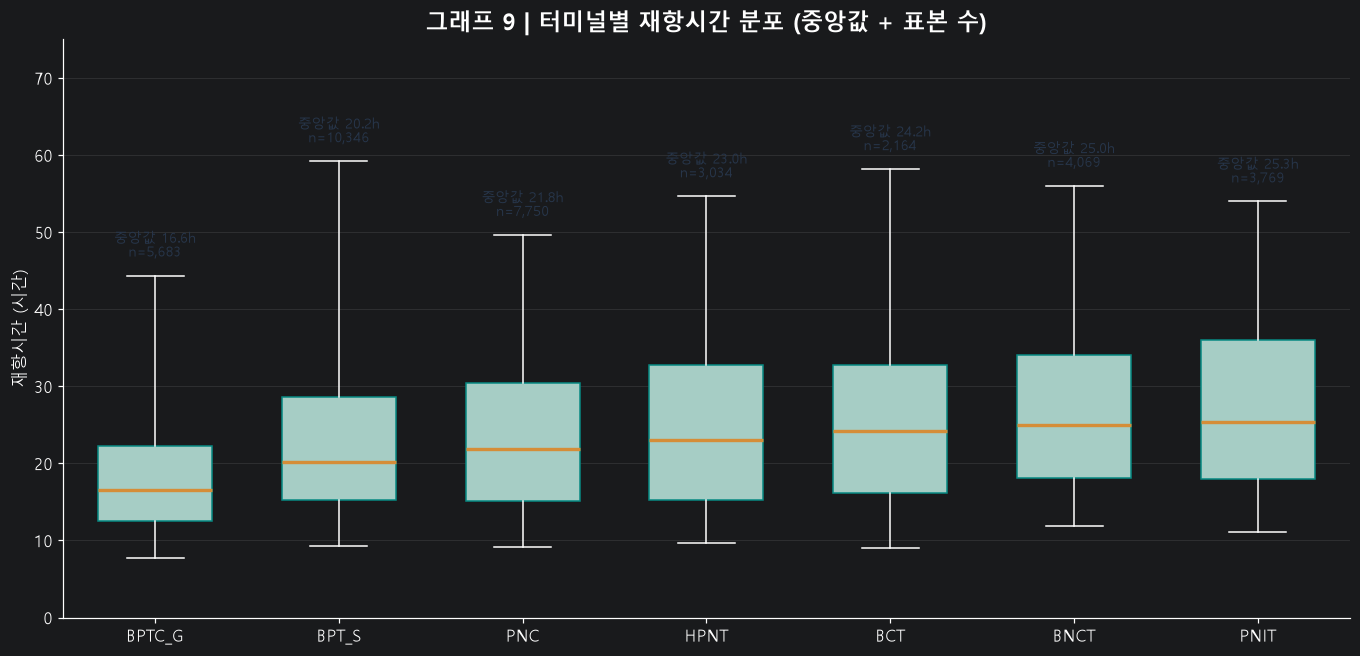

**데이터에서 읽기:** 터미널별 중앙값 범위는 **16.6~25.3시간**입니다. 선박 구성·시기·작업량을 통제하지 않은 단순 비교입니다.

In [15]:
term=dw.groupby('터미널')['재항시간_h'].agg(n='size',med='median',p90=lambda s:s.quantile(.90)).sort_values('med')
terms=term.index.tolist();term_data=[dw.loc[dw['터미널']==t,'재항시간_h'].values for t in terms]
fig,ax=plt.subplots(figsize=(12.5,6.1))
bp=ax.boxplot(term_data,patch_artist=True,showfliers=False,whis=(5,95),widths=.62)
for b in bp['boxes']: b.set(facecolor='#A6CDC5',edgecolor=TEAL)
for m in bp['medians']:m.set(color=ORANGE,linewidth=2.2)
ax.set_xticks(range(1,len(term)+1),terms)
ax.set_ylabel('재항시간 (시간)');ax.set_ylim(0,75)
ax.set_title('그래프 9 | 터미널별 재항시간 분포 (중앙값 + 표본 수)')
for i,(t,row) in enumerate(term.iterrows(),start=1):
    y_label = np.quantile(term_data[i-1], .95) + 2
    ax.text(i, y_label, f"중앙값 {row['med']:.1f}h\nn={row['n']:,.0f}",
            ha='center',va='bottom',fontsize=9,color='#27364B')
ax.grid(axis='y',alpha=.18)
fig.tight_layout(); save_show('09_터미널별_재항시간_상자그림',fig)
display(Markdown(f"**데이터에서 읽기:** 터미널별 중앙값 범위는 **{term['med'].min():.1f}~{term['med'].max():.1f}시간**입니다. 선박 구성·시기·작업량을 통제하지 않은 단순 비교입니다."))

## 그래프 10. 총톤수와 터미널을 함께 보면?

같은 터미널이라도 큰 배와 작은 배가 머무는 시간은 다를 수 있다. 반대로 크기가 비슷한 배라도 터미널에 따라 다를 수 있다. **터미널 × 크기 구간별 재항시간 중앙값**을 하나의 그림에 담았다.

- 위의 GT 10,000 단위는 칸이 너무 많아서 이 그림에서만 **5개 큰 구간**으로 묶었다.
- 각 칸의 글자는 `중앙값 시간 (표본 n)`을 의미한다.
- **표본이 30건 미만인 칸은 수치 대신 ‘표본부족’**으로 표시한다. 데이터가 0건인 칸은 빈 칸으로 구분한다.

이 그림은 기상 영향 분석 전에 **크기와 터미널을 동시에 고려할 필요**가 있는지 확인하는 데 유용하다.

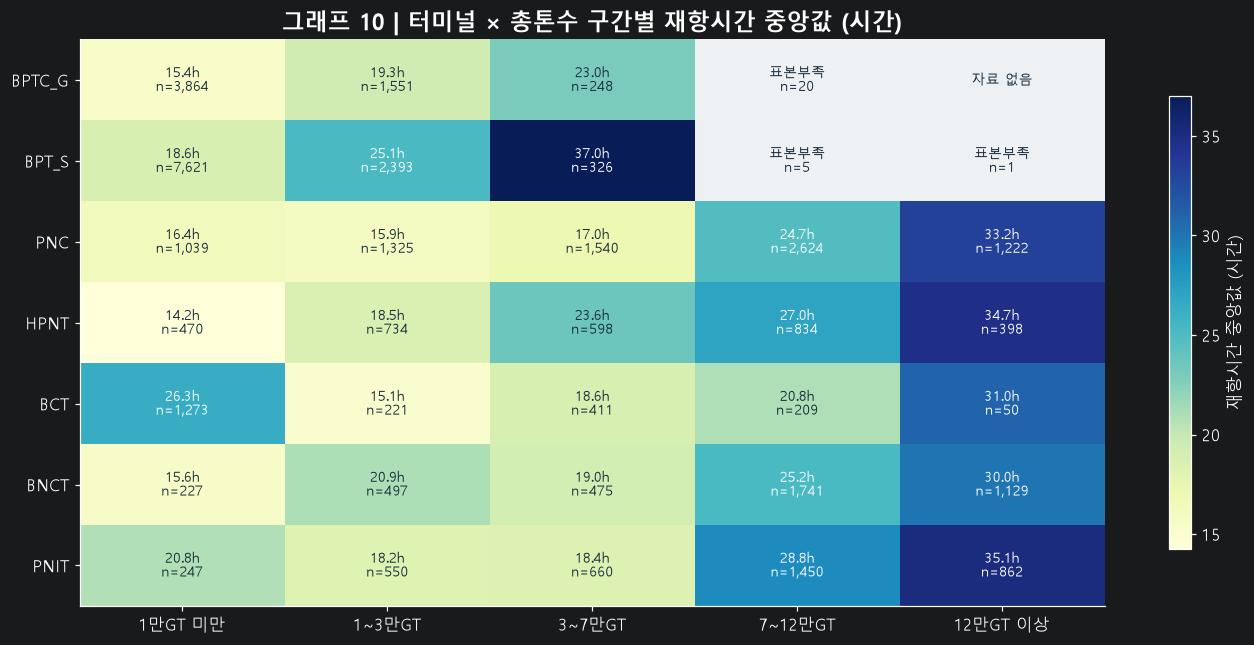

In [16]:
SIZE_EDGES=[0,10_000,30_000,70_000,120_000,np.inf]
SIZE_NAMES=['1만GT 미만','1~3만GT','3~7만GT','7~12만GT','12만GT 이상']
dw['크기_광역'] = pd.cut(dw['총톤수_GT'],bins=SIZE_EDGES,labels=SIZE_NAMES,right=False)
pivot_med=dw.pivot_table(index='터미널',columns='크기_광역',values='재항시간_h',aggfunc='median',observed=True).reindex(index=terms,columns=SIZE_NAMES)
pivot_n=dw.pivot_table(index='터미널',columns='크기_광역',values='재항시간_h',aggfunc='size',observed=True).reindex(index=terms,columns=SIZE_NAMES).fillna(0).astype(int)
masked=pivot_med.where(pivot_n>=MIN_HEATMAP_CELL_N)
fig,ax=plt.subplots(figsize=(12.6,6.0))
arr=masked.to_numpy(dtype=float)
cmap=plt.get_cmap('YlGnBu').copy();cmap.set_bad('#EDF1F4')
im=ax.imshow(np.ma.masked_invalid(arr),aspect='auto',cmap=cmap)
ax.set_xticks(range(len(SIZE_NAMES)),SIZE_NAMES)
ax.set_yticks(range(len(terms)),terms)
ax.set_title('그래프 10 | 터미널 × 총톤수 구간별 재항시간 중앙값 (시간)')
finite=arr[np.isfinite(arr)]
cutoff=np.median(finite) if len(finite) else 0
for i in range(len(terms)):
    for j in range(len(SIZE_NAMES)):
        n=int(pivot_n.iloc[i,j]);v=arr[i,j]
        if n==0:txt='자료 없음'
        elif n<MIN_HEATMAP_CELL_N:txt=f'표본부족\nn={n}'
        else:txt=f'{v:.1f}h\nn={n:,}'
        ax.text(j,i,txt,ha='center',va='center',fontsize=9,
                color=('white' if np.isfinite(v) and v>=cutoff*1.15 else '#182B3B'))
fig.colorbar(im,ax=ax,label='재항시간 중앙값 (시간)',shrink=.8)
fig.tight_layout(); save_show('10_터미널_총톤수_재항시간_히트맵',fig)

## 그래프 11. 터미널별 재항시간은 해마다 변했을까?

나중에 기상을 비교할 때 동일한 터미널이라도 연도별로 평소 재항시간이 바뀔 수 있다. 이를 확인하기 위한 **터미널별 연도 중앙값 선그래프**다.

**중요:** BCT는 이 자료에서 2022년부터 등장하므로, 2020~2021년을 '재항 0시간'으로 그리지 않고 비워둔다. 선은 자료가 존재하는 연도만 연결한다.

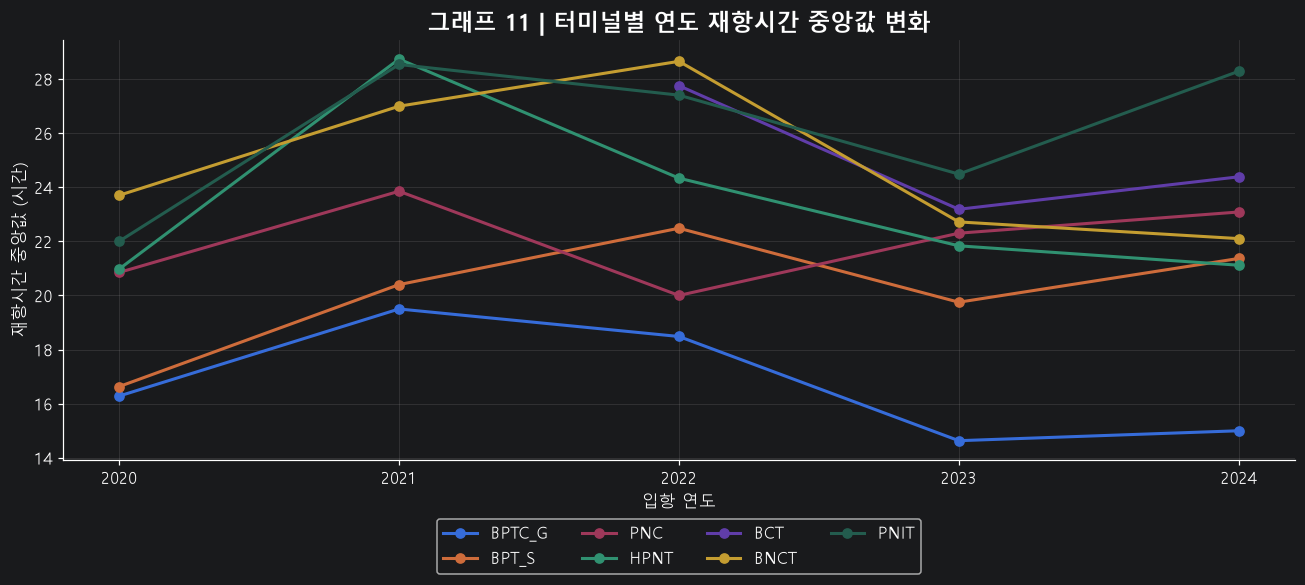

In [17]:
term_year=dw.groupby(['입항연도','터미널'])['재항시간_h'].agg(
    n='size',med='median').reset_index()
fig,ax=plt.subplots(figsize=(12,5.5))
for t in terms:
    sub=term_year.loc[(term_year['터미널']==t) & (term_year['n']>=30)].sort_values('입항연도')
    ax.plot(sub['입항연도'],sub['med'],marker='o',linewidth=2,label=t)
ax.set_xticks(range(START_YEAR,END_YEAR+1))
ax.set_xlabel('입항 연도');ax.set_ylabel('재항시간 중앙값 (시간)')
ax.set_title('그래프 11 | 터미널별 연도 재항시간 중앙값 변화')
ax.legend(ncol=4,loc='upper center',bbox_to_anchor=(.5,-.12));ax.grid(alpha=.2)
fig.tight_layout(); save_show('11_터미널별_연도_재항시간',fig)

# 3. 산점도와 상관계수(Corr) — 함께 움직이는 관계가 있을까?

앞의 11개 그래프에서는 **언제 입항이 많고 어떤 선박이 오래 머무는지**를 따로 보았습니다. 이번에는 두 지표가 함께 변화하는지 확인합니다.

### 아주 쉽게 이해하기
- **산점도:** 점 하나는 선박 1건 또는 날짜 1일을 의미합니다. 점들이 오른쪽 위로 올라가는 모양이면 두 값이 함께 커지는 경향입니다.
- **Pearson r:** **직선 형태의 관계**를 측정합니다. 극단값에 영향을 크게 받을 수 있습니다.
- **Spearman ρ(스피어만):** 값을 작은 순서에서 큰 순서로 매겼을 때, **크기 순서가 함께 변하는 관계**를 측정합니다. 완벽한 직선이 아니어도 경향을 찾는 데 유용합니다.
- 둘 다 **-1부터 +1 사이**의 값입니다. **양수**는 함께 커지는 경향, **음수**는 한쪽이 커질 때 다른 쪽은 작아지는 경향, **0 근처**는 뚜렷한 경향이 약함을 의미합니다.
- **상관계수는 원인·결과를 증명하지 않습니다.** 계절·선박 크기·터미널·작업량 등의 영향을 함께 살펴봐야 합니다.

**꼭 기억할 분석 기준:** 아래의 선박 단위 상관계수는 `재항시간_h > 10분`인 모든 유효 기록을 계산에 사용합니다. 산점도에 점이 너무 많을 경우 **화면에만 일부를 표시**하고, **상관계수는 전체 유효 표본으로 계산**합니다. 화면의 y축을 잘라 보여주는 경우에도 통계값은 자르지 않습니다.

**자료 범위:** 기존과 동일하게 `매칭성공` 시트만, 2020~2024년을 기본으로 사용합니다.

In [18]:
# 상관계수 계산 도우미: x/y가 둘 다 있는 관측치에 대해서만 계산
CORR_SCATTER_MAX = 12000     # 그래프 표시용 최대 점 수. 계수 계산에는 적용하지 않음
MIN_TERMINAL_DAILY_N = 3     # 터미널별 하루 재항시간 중앙값이 지나치게 불안정하지 않도록 한 기준


def corr_pair(data, x_col, y_col):
    both = data[[x_col, y_col]].replace([np.inf, -np.inf], np.nan).dropna()
    if len(both) < 3 or both[x_col].nunique() < 2 or both[y_col].nunique() < 2:
        return len(both), np.nan, np.nan
    return (len(both),
            both[x_col].corr(both[y_col], method='pearson'),
            both[x_col].corr(both[y_col], method='spearman'))


def corr_label(stats):
    n, pearson, spearman = stats
    return f'Pearson r = {pearson:+.3f}  |  Spearman ρ = {spearman:+.3f}  |  n = {n:,}'


def chart_points(data, max_count=CORR_SCATTER_MAX):
    return data.sample(n=min(len(data), max_count), random_state=42) if len(data) else data.copy()


def display_corr(stats, comment=''):
    display(Markdown(f'**계산 결과:** `{corr_label(stats)}`  ' + (f'  \n{comment}' if comment else '')))

corr_results = []
def add_corr_result(name, level, data, x, y, remarks=''):
    n,r,rho = corr_pair(data,x,y)
    corr_results.append({'비교':name, '자료단위':level, '표본수':n,
                         'Pearson_r':r, 'Spearman_rho':rho, '해석주의':remarks})
    return n,r,rho

print('상관분석 설정: 전체 표본으로 Pearson / Spearman 계산, 산점도 표시는 표본추출할 수 있음')

상관분석 설정: 전체 표본으로 Pearson / Spearman 계산, 산점도 표시는 표본추출할 수 있음


## 그래프 12. 총톤수(GT)가 클수록 재항시간도 길어질까?

**점 하나 = 선박 입항 1건**입니다. 가로축은 배의 크기(총톤수), 세로축은 부산항 입항부터 출항까지 걸린 시간입니다.

- 총톤수 범위가 커서 **가로축은 로그 눈금**을 사용합니다. 로그 눈금에서는 같은 가로 길이가 같은 *배수 차이*를 뜻합니다.
- 점이 겹치지 않도록 표시 점 수를 제한하고 투명하게 그렸습니다.
- **주황색 선은 총톤수 분위 구간별 재항시간 중앙값**입니다. 회귀선이 아니라 전반적인 흐름을 쉽게 읽는 기준입니다.
- 그림의 세로축은 *표시용으로만* 99백분위수까지만 보여줍니다. 상관계수는 초장기 체류를 포함한 **전체 유효 선박**을 기준으로 계산합니다.

**날씨 분석 전 의미:** 배가 큰지 작은지를 고려하지 않고 재항시간을 비교하면, 선박 구성의 차이를 날씨 영향으로 오해할 수 있습니다.

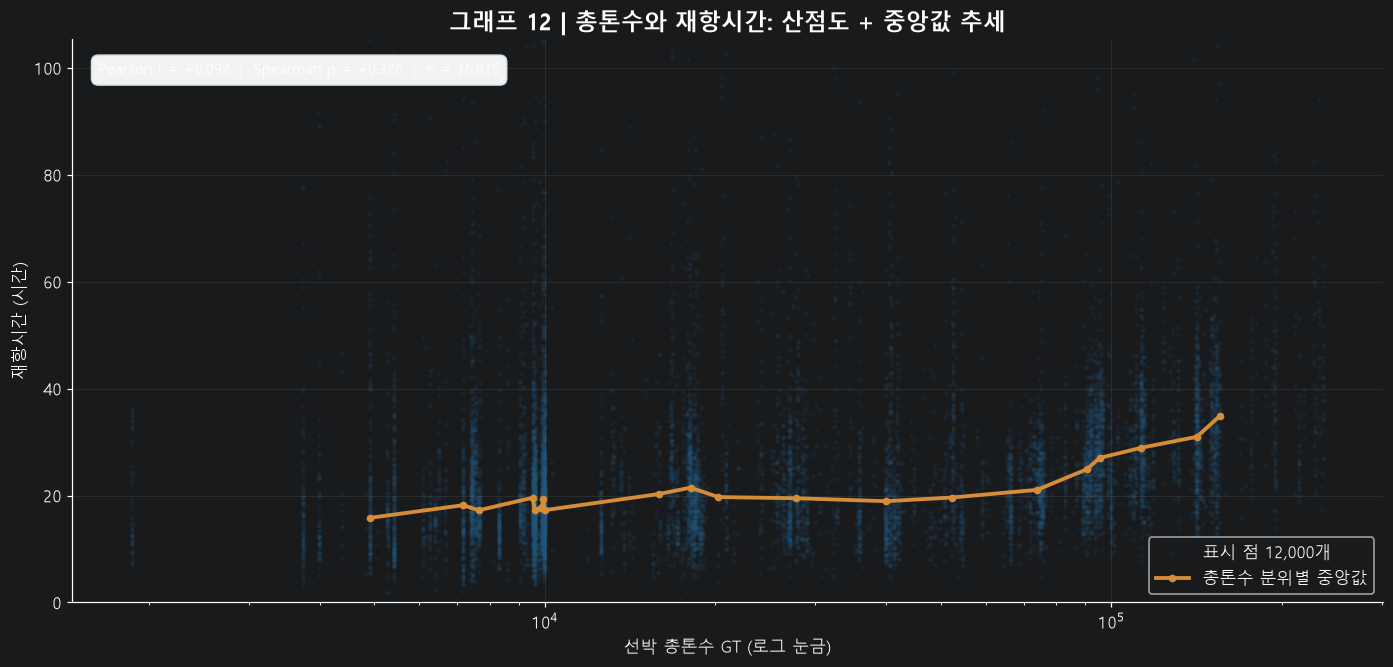

**계산 결과:** `Pearson r = +0.092  |  Spearman ρ = +0.326  |  n = 36,815`    
Pearson과 Spearman 값이 다른 경우 긴 체류 기록 또는 곡선형 관계의 영향을 확인하세요.

In [19]:
gt_pair = dw[['총톤수_GT','재항시간_h']].replace([np.inf,-np.inf], np.nan).dropna().copy()
stat_gt = add_corr_result('총톤수 ↔ 선박별 재항시간', '선박 입항 1건', gt_pair,
                          '총톤수_GT','재항시간_h', '선박 크기와 작업량·터미널이 함께 달라질 수 있음')
points=chart_points(gt_pair)
plot_ylim=float(gt_pair['재항시간_h'].quantile(.99))
fig,ax=plt.subplots(figsize=(12.8,6.2))
ax.scatter(points['총톤수_GT'],points['재항시간_h'],s=8,alpha=.13,c=BLUE,linewidths=0,
           label=f'표시 점 {len(points):,}개')
quantile_bins=pd.qcut(gt_pair['총톤수_GT'],q=20,duplicates='drop')
trend=gt_pair.groupby(quantile_bins,observed=True).agg(x=('총톤수_GT','median'),y=('재항시간_h','median'),n=('재항시간_h','size'))
ax.plot(trend['x'],trend['y'],color=ORANGE,lw=2.5,marker='o',markersize=4,label='총톤수 분위별 중앙값')
ax.set_xscale('log'); ax.set_ylim(0,plot_ylim);ax.set_xlabel('선박 총톤수 GT (로그 눈금)')
ax.set_ylabel('재항시간 (시간)')
ax.set_title('그래프 12 | 총톤수와 재항시간: 산점도 + 중앙값 추세')
ax.text(.02,.96,corr_label(stat_gt),transform=ax.transAxes,va='top',fontsize=10,
        bbox=dict(facecolor='white',edgecolor='#D7E3EA',boxstyle='round,pad=.45',alpha=.95))
ax.grid(alpha=.15);ax.legend(loc='lower right')
fig.tight_layout(); save_show('12_총톤수_재항시간_산점도_corr',fig)
display_corr(stat_gt,'Pearson과 Spearman 값이 다른 경우 긴 체류 기록 또는 곡선형 관계의 영향을 확인하세요.')

## 그래프 13. 하루 입항이 많은 날, 재항시간도 길어질까?

**점 하나 = 날짜 1일**입니다. x축은 그날 매칭된 선박의 입항 건수, y축은 **그날 입항한 선박들**이 결국 출항하기까지 걸린 재항시간의 중앙값입니다.

- 연도별 색을 다르게 표시하고 전체 날짜를 대상으로 **참고용 직선 추세선**을 그립니다.
- 입항 건수가 0인 날은 재항시간 중앙값을 정의할 수 없어 산점도와 상관계수에서 제외합니다.
- 이 그림의 y값은 *그날 즉시 관측 가능한 대기시간*이 아니라, 그날 입항한 선박들이 출항한 뒤 산출한 **최종 체류시간**입니다.

**해석 주의:** 입항 건수가 많다는 이유만으로 재항시간이 길어졌다고 주장할 수 없습니다. 입항량이 적은 이유가 운영 중단·계절성·출항 지연일 수도 있습니다.

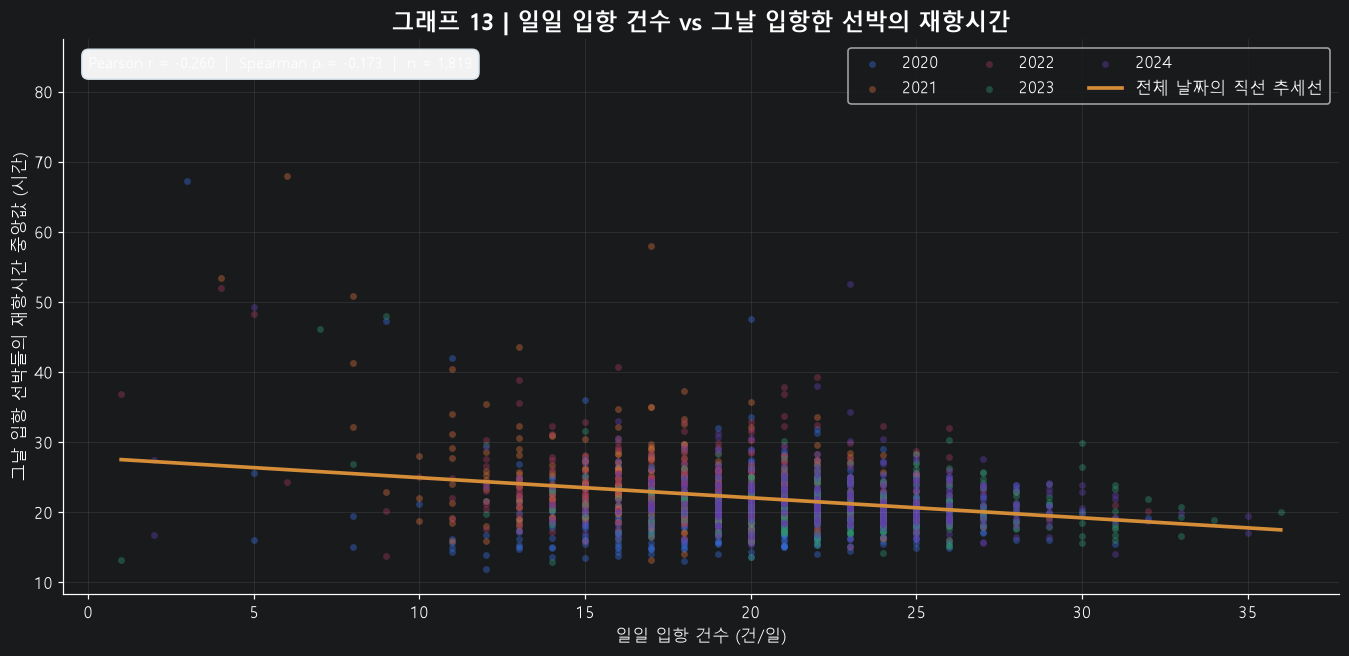

**계산 결과:** `Pearson r = -0.260  |  Spearman ρ = -0.173  |  n = 1,819`  

연도별 비교 (하루를 한 개 표본으로 사용)


,연도,날짜수,Pearson_r,Spearman_rho
0,2020,363,-0.155,0.086
1,2021,364,-0.309,-0.169
2,2022,362,-0.253,-0.187
3,2023,364,-0.199,-0.118
4,2024,366,-0.205,-0.153


In [20]:
daily_dwell=dw.groupby('입항일')['재항시간_h'].agg(
    재항시간_중앙값='median',재항시간_평균='mean',재항시간_P90=lambda s:s.quantile(.9),
    재항시간_집계건수='size')
day_joint=daily[['입항건수','연도','월','요일번호']].join(daily_dwell,how='left')
day_obs=day_joint.dropna(subset=['재항시간_중앙값']).copy()
stat_day=add_corr_result('일일 입항건수 ↔ 해당일 입항 선박의 재항시간 중앙값',
                         '입항 날짜 1일',day_obs,'입항건수','재항시간_중앙값',
                         '0건 날짜 제외; 재항시간은 출항 후 확정된 값')
fig,ax=plt.subplots(figsize=(12.4,6.1))
for yr, part in day_obs.groupby('연도'):
    ax.scatter(part['입항건수'],part['재항시간_중앙값'],s=20,alpha=.42,label=str(yr),linewidths=0)
if day_obs['입항건수'].nunique()>1:
    coef=np.polyfit(day_obs['입항건수'],day_obs['재항시간_중앙값'],1)
    xs=np.linspace(day_obs['입항건수'].min(),day_obs['입항건수'].max(),101)
    ax.plot(xs,np.polyval(coef,xs),c=ORANGE,lw=2.4,label='전체 날짜의 직선 추세선')
ax.set_xlabel('일일 입항 건수 (건/일)');ax.set_ylabel('그날 입항 선박들의 재항시간 중앙값 (시간)')
ax.set_title('그래프 13 | 일일 입항 건수 vs 그날 입항한 선박의 재항시간')
ax.text(.02,.97,corr_label(stat_day),transform=ax.transAxes,va='top',fontsize=10,
        bbox=dict(facecolor='white',edgecolor='#D7E3EA',boxstyle='round,pad=.45',alpha=.95))
ax.grid(alpha=.16);ax.legend(ncol=3,loc='upper right')
fig.tight_layout(); save_show('13_일일입항건수_재항중앙값_산점도_corr',fig)
display_corr(stat_day)
print('연도별 비교 (하루를 한 개 표본으로 사용)')
rows=[]
for year,group in day_obs.groupby('연도'):
    n,r,rho=corr_pair(group,'입항건수','재항시간_중앙값')
    rows.append({'연도':year,'날짜수':n,'Pearson_r':r,'Spearman_rho':rho})
display(pd.DataFrame(rows).round(3))

## 그래프 14. 입항과 재항시간의 관계는 터미널마다 같을까?

**점 하나 = 특정 터미널의 입항 날짜 1일**입니다. x축은 해당 터미널의 하루 입항 건수, y축은 해당 날짜 그 터미널에 입항한 선박들의 재항시간 중앙값입니다.

- **하루 입항이 3건 이상인 터미널·날짜**만 비교합니다(안정적인 중앙값을 위한 선택). 3건 미만이었던 날까지 포함한 결과와는 다를 수 있습니다.
- 터미널마다 자료가 존재하는 연도가 다릅니다. 패널 옆에 붙은 표본 수는 **일수**이지 선박 건수가 아닙니다.
- 각 패널에 **Spearman ρ**를 표시합니다. 값을 서로 순위 매기는 방식으로 비교합니다.
- y축은 **화면에서만** 99백분위수까지 표시하여 주요 분포를 보기 쉽게 합니다. 계수 계산에는 이 제한을 적용하지 않습니다.

**왜 보나요?** 전체 항만 단위에서 보이는 관계가 특정 터미널의 선박 크기 구성 때문에 생긴 것인지 구분할 실마리를 줍니다.

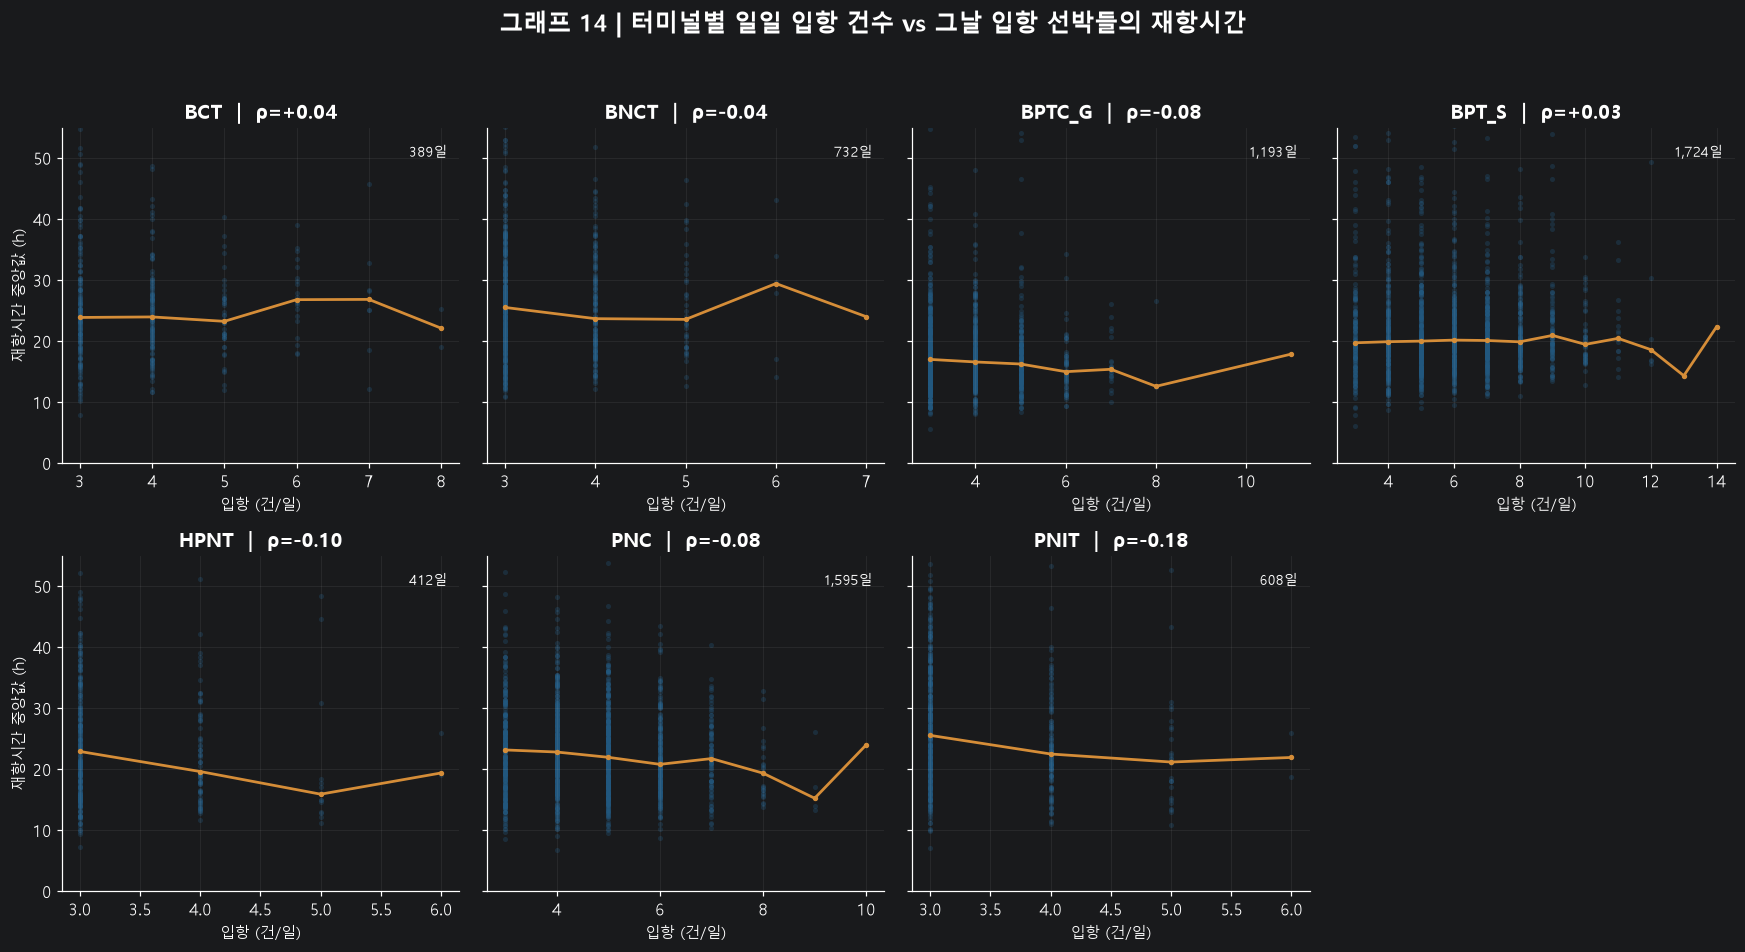

,터미널,날짜수,Pearson_r,Spearman_rho
0,BCT,389,0.022,0.038
1,BNCT,732,-0.002,-0.036
2,BPTC_G,1193,-0.074,-0.082
3,BPT_S,1724,-0.020,0.031
4,HPNT,412,-0.058,-0.103
5,PNC,1595,-0.095,-0.083
6,PNIT,608,-0.170,-0.175


In [21]:
term_days=dw.groupby(['터미널','입항일']).agg(
    입항건수=('재항시간_h','size'),재항시간_중앙값=('재항시간_h','median')).reset_index()
term_days_ok=term_days.loc[term_days['입항건수']>=MIN_TERMINAL_DAILY_N].copy()
term_corr=[]
term_names=sorted(term_days['터미널'].unique())
fig,axes=plt.subplots(2,4,figsize=(16,8.8),sharey=True)
axes=axes.ravel()
q99=float(term_days_ok['재항시간_중앙값'].quantile(.99))
for i,name in enumerate(term_names):
    ax=axes[i]
    part=term_days_ok.loc[term_days_ok['터미널']==name]
    n,r,rho=corr_pair(part,'입항건수','재항시간_중앙값')
    term_corr.append({'터미널':name,'날짜수':n,'Pearson_r':r,'Spearman_rho':rho})
    ax.scatter(part['입항건수'],part['재항시간_중앙값'],s=11,c=BLUE,alpha=.3,linewidths=0)
    if part['입항건수'].nunique()>=2:
        xmed=part.groupby('입항건수')['재항시간_중앙값'].median()
        ax.plot(xmed.index,xmed.values,color=ORANGE,lw=1.8,marker='o',markersize=2.5)
    ax.set_title(f'{name}  |  ρ={rho:+.2f}',fontsize=13)
    ax.set_xlabel('입항 (건/일)',fontsize=10)
    ax.text(.97,.95,f'{n:,}일',ha='right',va='top',transform=ax.transAxes,fontsize=9)
    ax.grid(alpha=.13)
    if i%4==0: ax.set_ylabel('재항시간 중앙값 (h)',fontsize=10)
for ax in axes[len(term_names):]:ax.axis('off')
for ax in axes[:len(term_names)]:ax.set_ylim(0,q99)
fig.suptitle('그래프 14 | 터미널별 일일 입항 건수 vs 그날 입항 선박들의 재항시간',fontsize=16,fontweight='bold')
fig.tight_layout(rect=[0,0,1,.95]); save_show('14_터미널별_일일입항_재항_산점도_corr',fig)
term_corr_df=pd.DataFrame(term_corr)
display(term_corr_df.round(3))

## 그래프 15. 작업량이 많은 선박은 오래 머무는 경향이 있을까?

**점 하나 = 선박 입항 1건**입니다. 가로축은 `터미널_총작업량` 원본 수량, 세로축은 부산항 재항시간입니다.

- `터미널_총작업량`의 **수량 단위가 BOX/TEU 중 무엇인지 원자료 설명을 확인해야 하므로** 여기서는 '원본 수량'으로만 표시합니다.
- 작업량은 입항 당시 이미 알려진 예측값이 아니라 사후 실적일 수 있습니다.
- 주황색 선은 **작업량 분위별 재항시간 중앙값**이며 회귀선이 아닙니다.
- 그림에는 재항시간을 99백분위수까지만 표시해도 상관계수에는 모든 유효 기록을 넣습니다.

**날씨 분석 전 의미:** 재항시간에 대한 날씨 효과를 논할 때 작업량이 다른 선박들을 단순 비교하면 결과가 왜곡될 수 있습니다.

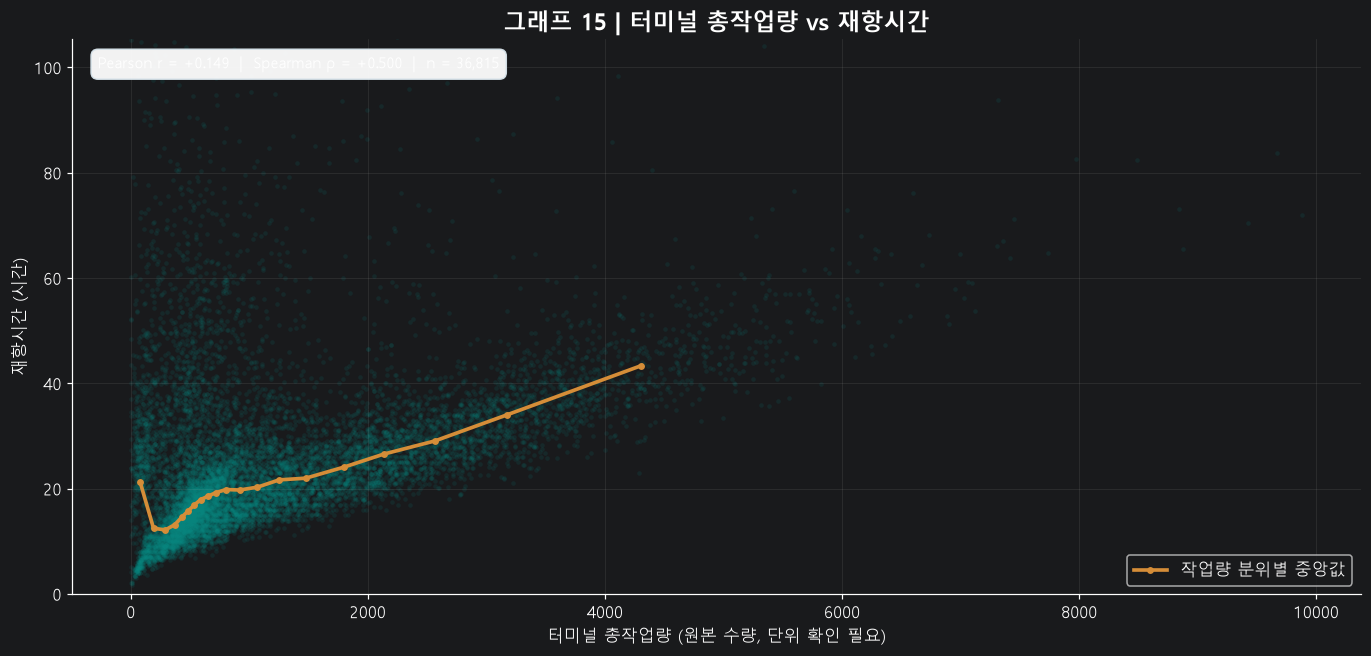

**계산 결과:** `Pearson r = +0.149  |  Spearman ρ = +0.500  |  n = 36,815`  

In [22]:
work_pair=dw[['터미널_총작업량','재항시간_h']].replace([np.inf,-np.inf],np.nan).dropna().copy()
work_pair=work_pair.loc[work_pair['터미널_총작업량']>=0]
stat_work=add_corr_result('터미널 총작업량 ↔ 선박별 재항시간','선박 입항 1건',work_pair,
                           '터미널_총작업량','재항시간_h',
                           '총작업량의 단위와 수집 시점을 확인할 것; 사후 실적')
pts=chart_points(work_pair)
fig,ax=plt.subplots(figsize=(12.6,6.1))
ax.scatter(pts['터미널_총작업량'],pts['재항시간_h'],s=9,alpha=.13,c=TEAL,linewidths=0)
work_bin=pd.qcut(work_pair['터미널_총작업량'].rank(method='first'),q=20,duplicates='drop')
work_trend=work_pair.groupby(work_bin,observed=True).agg(
    x=('터미널_총작업량','median'),y=('재항시간_h','median'))
ax.plot(work_trend['x'],work_trend['y'],color=ORANGE,lw=2.4,marker='o',markersize=3.5,label='작업량 분위별 중앙값')
ax.set_ylim(0,float(work_pair['재항시간_h'].quantile(.99)))
ax.set_xlabel('터미널 총작업량 (원본 수량, 단위 확인 필요)')
ax.set_ylabel('재항시간 (시간)')
ax.set_title('그래프 15 | 터미널 총작업량 vs 재항시간')
ax.text(.02,.97,corr_label(stat_work),transform=ax.transAxes,va='top',fontsize=10,
        bbox=dict(facecolor='white',edgecolor='#D7E3EA',boxstyle='round,pad=.45',alpha=.95))
ax.grid(alpha=.15);ax.legend(loc='lower right')
fig.tight_layout(); save_show('15_총작업량_재항시간_산점도_corr',fig)
display_corr(stat_work)

## 그래프 16. 여러 숫자 지표의 상관계수를 한 번에 확인하기

이번에는 **선박 입항 1건을 한 행으로 놓고**, 총톤수·작업량·Shift수량·양하톤수·재항시간의 관계를 같이 봅니다.

- 왼쪽은 **Pearson 상관계수**, 오른쪽은 **Spearman 상관계수**입니다.
- 대각선은 같은 변수를 자기 자신과 비교하므로 항상 1입니다.
- **터미널명은 숫자가 아닌 범주**이기 때문에 1, 2, 3 같은 번호를 매겨 상관분석하지 않습니다.
- 이 두 표는 **선박 단위의 상관관계만** 담습니다. 일일 입항 건수와 일일 재항시간의 상관계수는 별도 그래프 13·14에 있습니다. 서로 다른 단위의 관측치를 섞으면 오해할 수 있습니다.

**중요:** 이 상관행렬은 변수 간 단순 관계를 보여줄 뿐입니다. 기상 영향의 인과적 크기를 추정하는 분석은 아닙니다.

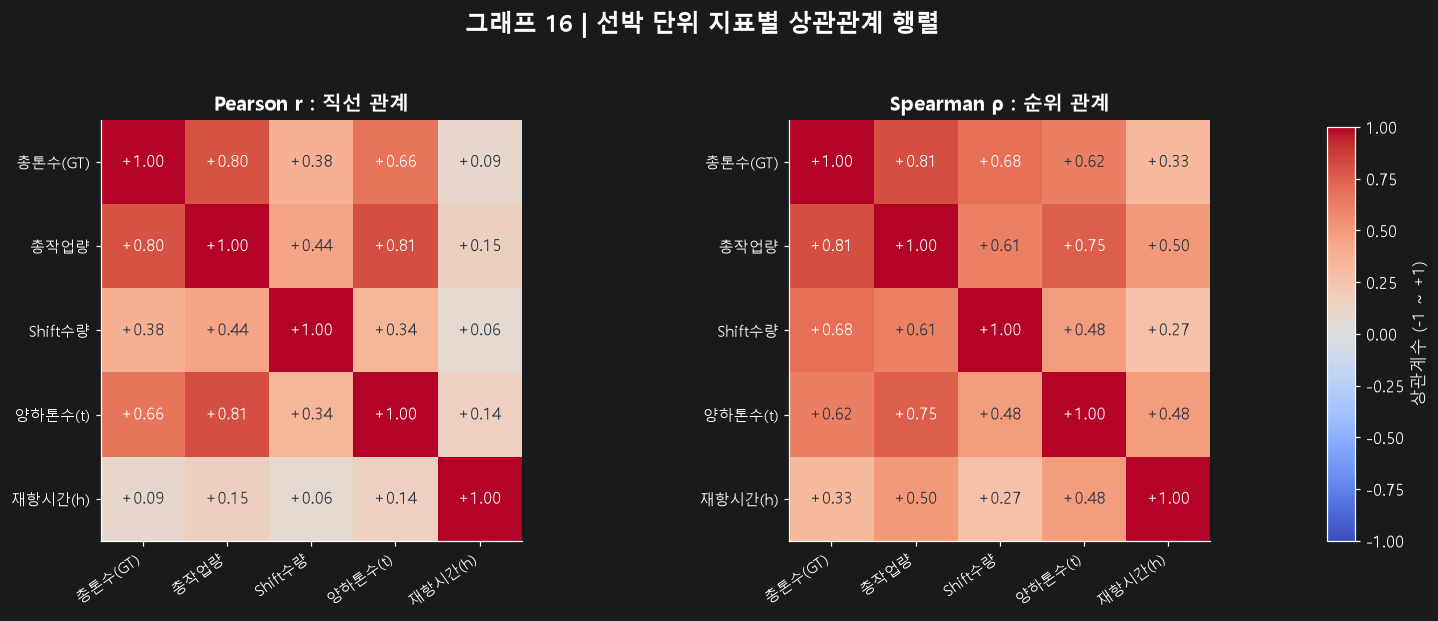

### 이번에 계산한 주요 상관계수 모음

,비교,자료단위,표본수,Pearson_r,Spearman_rho
0,총톤수 ↔ 선박별 재항시간,선박 입항 1건,36815,0.092,0.326
1,일일 입항건수 ↔ 해당일 입항 선박의 재항시간 중앙값,입항 날짜 1일,1819,-0.260,-0.173
2,터미널 총작업량 ↔ 선박별 재항시간,선박 입항 1건,36815,0.149,0.500


※ corr는 변수 간 연관성을 뜻하며, 날씨·입항 집중·작업량 중 무엇이 원인인지는 별도 분석 필요


In [23]:
corr_cols={
    '총톤수_GT':'총톤수(GT)',
    '터미널_총작업량':'총작업량',
    '터미널_Shift수량':'Shift수량',
    '양하톤수':'양하톤수(t)',
    '재항시간_h':'재항시간(h)'
}
corr_frame=dw[list(corr_cols)].apply(pd.to_numeric,errors='coerce').rename(columns=corr_cols)
matrices=[corr_frame.corr(method='pearson'),corr_frame.corr(method='spearman')]
fig,axs=plt.subplots(1,2,figsize=(14.2,6.6))
for ax,mat,subttl in zip(axs,matrices,['Pearson r : 직선 관계','Spearman ρ : 순위 관계']):
    im=ax.imshow(mat.values,vmin=-1,vmax=1,cmap='coolwarm')
    labs=mat.columns.tolist()
    ax.set_xticks(range(len(labs)),labs,rotation=35,ha='right',fontsize=10)
    ax.set_yticks(range(len(labs)),labs,fontsize=10)
    ax.set_title(subttl,fontsize=13)
    for i in range(len(labs)):
        for j in range(len(labs)):
            v=mat.iloc[i,j]
            ax.text(j,i,f'{v:+.2f}',ha='center',va='center',fontsize=11,
                    color=('white' if abs(v)>.65 else '#203040'))
fig.subplots_adjust(top=.83,bottom=.25,left=.08,right=.86,wspace=.30)
cax=fig.add_axes([.90,.25,.018,.57])
fig.colorbar(im,cax=cax,label='상관계수 (-1 ~ +1)')
fig.suptitle('그래프 16 | 선박 단위 지표별 상관관계 행렬',fontweight='bold',fontsize=16)
save_show('16_선박변수_Pearson_Spearman_상관행렬',fig)
summary_corr=pd.DataFrame(corr_results)
display(Markdown('### 이번에 계산한 주요 상관계수 모음'))
display(summary_corr[['비교','자료단위','표본수','Pearson_r','Spearman_rho']].round(3))
print('※ corr는 변수 간 연관성을 뜻하며, 날씨·입항 집중·작업량 중 무엇이 원인인지는 별도 분석 필요')

In [24]:
# 산점도에서 사용한 계산 결과를 날씨 분석 때 재사용하도록 저장
summary_corr.to_csv(OUTPUT_DIR/'상관분석_주요지표.csv',index=False,encoding='utf-8-sig')
day_joint.reset_index().rename(columns={'날짜':'입항일'}).to_csv(
    OUTPUT_DIR/'일별_입항건수_재항시간_상관기초.csv',index=False,encoding='utf-8-sig')
term_corr_df.to_csv(OUTPUT_DIR/'터미널별_일일입항_상관계수.csv',index=False,encoding='utf-8-sig')
term_days_ok.to_csv(OUTPUT_DIR/'터미널별_일일입항_재항시간_산점도데이터.csv',index=False,encoding='utf-8-sig')
matrices[0].to_csv(OUTPUT_DIR/'선박변수_Pearson_상관행렬.csv',encoding='utf-8-sig')
matrices[1].to_csv(OUTPUT_DIR/'선박변수_Spearman_상관행렬.csv',encoding='utf-8-sig')
print('상관계수·산점도 분석에 필요한 집계 CSV 저장 완료')

상관계수·산점도 분석에 필요한 집계 CSV 저장 완료


# 4. 전체 결과 정리 및 다음 단계

## 그래프를 종합해서 읽는 순서

1. **평소 입항량 기준선:** 그래프 1~4에서 연도와 월 차이를 먼저 본다. 월별 총건수가 아닌 `건/일`로 비교한다.
2. **요일·시간 차이:** 그래프 5~6에서 같은 요일과 같은 시간대의 평소 수준을 파악한다.
3. **평소 재항시간 기준선:** 그래프 7~9에서 선박 크기·터미널별 중앙값과 P90 차이를 확인한다.
4. **크기와 터미널을 동시에:** 그래프 10에서 같은 크기대의 터미널별 차이를 보고, 그래프 11에서 연도별 변화도 확인한다.

5. **산점도와 Corr:** 그래프 12~16에서 총톤수·작업량·일일 입항과 재항시간 간 단순 관계를 보고, Pearson과 Spearman 차이도 읽는다.

## 날씨 데이터와 합칠 때 주의사항

- `입항일`을 단순히 날씨와 연결하기 전에, **기상 발생 시간과 입항 시각의 선후관계**를 고려한다.
- 하루 입항 건수가 0건인 날짜가 **실제로 0척인지 매칭 성공 데이터의 누락인지** 점검한다.
- 부산항 전체 운영성과로 해석하지 않고, **매칭된 입항 기록의 경향**으로 표현한다.
- 터미널별 입항 기록이 시작되는 연도가 다를 수 있으므로 **터미널별 관측기간을 따로 확인**한다.
- 재항시간이 오래 걸린 배를 임의로 삭제하지 말고, 의심 사례를 별도로 검토한다.
- 선박 크기·터미널·작업량 차이는 향후 날씨 효과 평가의 **교란 요인**일 수 있다.

## 생성되는 파일

다시 실행하면 이 노트북 옆의 `부산항_기초분석_산출물` 폴더에 16개 PNG 그래프와 요약 CSV가 저장된다. 원본 엑셀은 변경하지 않는다.

In [25]:
# 외부 날씨 자료와 결합할 때 사용할 기초 데이터 저장
save_daily=daily.reset_index().copy()
save_daily.to_csv(OUTPUT_DIR/'날짜별_입항건수_기초데이터.csv',index=False,encoding='utf-8-sig')
monthly.to_csv(OUTPUT_DIR/'연도월별_입항건수_요약.csv',index=False,encoding='utf-8-sig')
sizes.to_csv(OUTPUT_DIR/'총톤수구간별_재항시간_요약.csv',encoding='utf-8-sig')
term.to_csv(OUTPUT_DIR/'터미널별_재항시간_요약.csv',encoding='utf-8-sig')
term_year.to_csv(OUTPUT_DIR/'연도터미널별_재항시간_요약.csv',index=False,encoding='utf-8-sig')
print('저장 폴더:',OUTPUT_DIR)
print(f"그림: {len(list(OUTPUT_DIR.glob('*.png')))}개 / CSV: {len(list(OUTPUT_DIR.glob('*.csv')))}개")
print('모든 재항시간은 원본 시각 차이로 계산했고, 표의 재항시간 통계에는 상한값을 임의로 적용하지 않았습니다.')

저장 폴더: C:\work\Port_Cast_Final\1.Rawdata_EDA\Output\부산항_기초분석_산출물
그림: 22개 / CSV: 17개
모든 재항시간은 원본 시각 차이로 계산했고, 표의 재항시간 통계에는 상한값을 임의로 적용하지 않았습니다.


# 5. 장시간 체류 이상치가 입항 집중·양하량·작업량과 관련 있을까?

**핵심 질문:** "평소보다 오래 머문 선박이 입항이 많거나 작업량이 많은 날짜에 더 자주 등장하는가?"

### 중요: 서로 다른 두 종류의 이상치를 구분한다

1. **운영상 장시간 체류 이상치(이 섹션의 주 분석)**: `재항시간 = 출항일시 - 입항일시`가 **동일 터미널·유사 총톤수 구간**에 속한 배들의 **상위 5%보다 큰 경우**. 그룹 샘플 수가 30건 미만이면 해당 터미널 전체의 95백분위수를 임시로 적용한다. 이 구분은 기상 지연의 증거가 아닌 **장기 체류 후보**이다.
2. **시각 검증 이상치(보조 비교)**: 원본의 `터미널접안_시간관계검증 == '이상'`. 선박 접안 시각의 데이터 적합성 문제이지, 곧바로 운영 지연을 의미하지 않는다.

**왜 이상치 '건수'가 아니라 '발생률'을 볼까?** 입항이 많은 날은 배 자체가 많기 때문에 이상치도 더 많아지기 쉽다. 발생률(이상치 건수÷시간 분석이 가능한 선박 건수)을 사용하면 날짜별 물량 차이를 어느 정도 보정할 수 있다.

**일별 양하톤수·작업량의 의미:** 해당 날짜에 실제 처리된 물동량이 아닌 **그날 입항한 선박들에 연결된 실적의 합계**이다. 입항 당일 실제 하역량으로 해석하지 않는다.

**필터:** 이전 섹션의 기본 설정(2020~2024년, 기본 전체 선종)을 그대로 따른다. 실측 날씨가 아직 없으므로, 여기서 보이는 관계를 '날씨의 영향'으로 단정하지 않는다.

In [26]:
from matplotlib import patheffects

# 5.1 이상치 판정: 터미널 × 선박 총톤수 구간별 재항시간 상위 5%
LONG_STAY_QUANTILE = 0.95
MIN_REFERENCE_GROUP = 30
MIN_SHIPS_PER_DAY = 10  # 비율을 볼 때 하루 1~2건은 지나치게 흔들릴 수 있으므로 최소 10건

outlier_ship = dw.copy()
if '크기_광역' not in outlier_ship.columns:
    EDGES = [0,10_000,30_000,70_000,120_000,np.inf]
    LABELS = ['1만GT 미만','1~3만GT','3~7만GT','7~12만GT','12만GT 이상']
    outlier_ship['크기_광역'] = pd.cut(outlier_ship['총톤수_GT'], EDGES, labels=LABELS, right=False)

# 관측값이 충분한 그룹에선 그룹별 95백분위, 부족한 그룹에선 터미널별 95백분위 사용
ref = outlier_ship.groupby(['터미널','크기_광역'],observed=True)['재항시간_h'].agg(
    그룹건수='size',경계시간=lambda s:s.quantile(LONG_STAY_QUANTILE)).reset_index()
ref['임시경계_터미널'] = ref['터미널'].map(outlier_ship.groupby('터미널')['재항시간_h'].quantile(LONG_STAY_QUANTILE))
ref['적용경계시간'] = np.where(ref['그룹건수'] >= MIN_REFERENCE_GROUP, ref['경계시간'], ref['임시경계_터미널'])
outlier_ship = outlier_ship.merge(ref[['터미널','크기_광역','적용경계시간','그룹건수']],on=['터미널','크기_광역'],how='left',validate='many_to_one')
outlier_ship['장시간체류_이상'] = outlier_ship['재항시간_h'] > outlier_ship['적용경계시간']

# 수량 자료는 음수를 무효 처리하고, 시각으로 날짜를 정한다
numeric_features = ['양하톤수','터미널_양하수량','터미널_총작업량','터미널_순수물동량','총톤수']
full = df.copy()
for name in numeric_features:
    full[name] = pd.to_numeric(full[name],errors='coerce')
    full.loc[full[name] < 0, name] = np.nan

# 입항 건수: 분석 대상 선박 모두 / 일별 실적: 그날 입항한 선박과 연결된 총실적
ship_daily_count = full.groupby('입항일').size().rename('일일_입항건수')
daily_amounts = full.groupby('입항일').agg(**{
    '일일_양하톤수_입항선박합': ('양하톤수',lambda s:s.sum(min_count=1)),
    '일일_터미널양하수량_입항선박합': ('터미널_양하수량',lambda s:s.sum(min_count=1)),
    '일일_총작업량_입항선박합': ('터미널_총작업량',lambda s:s.sum(min_count=1)),
    '일일_순수물동량_입항선박합': ('터미널_순수물동량',lambda s:s.sum(min_count=1)),
    '일일_총톤수_입항선박합': ('총톤수',lambda s:s.sum(min_count=1))
})
ship_daily_outliers = outlier_ship.groupby('입항일')['장시간체류_이상'].agg(
    재항분석가능건수='size',장시간체류_건수='sum')

# 이전 날짜별 완전한 달력(all_days)을 그대로 활용
outlier_day = pd.DataFrame(index=all_days)
outlier_day.index.name='날짜'
outlier_day=outlier_day.join([ship_daily_count,daily_amounts,ship_daily_outliers])
outlier_day['일일_입항건수'] = outlier_day['일일_입항건수'].fillna(0).astype(int)
outlier_day['재항분석가능건수'] = outlier_day['재항분석가능건수'].fillna(0).astype(int)
outlier_day['장시간체류_건수'] = outlier_day['장시간체류_건수'].fillna(0).astype(int)
outlier_day['장시간체류_비율'] = np.where(
    outlier_day['재항분석가능건수'] > 0,
    outlier_day['장시간체류_건수'] / outlier_day['재항분석가능건수'],np.nan)

# 평소와 비교한 입항 집중: 같은 월·요일의 하루 입항 건수 중앙값(5년 통합)을 기준으로 함
outlier_day['연도'] = outlier_day.index.year
outlier_day['월'] = outlier_day.index.month
outlier_day['요일'] = outlier_day.index.day_of_week
outlier_day['평소_입항건수'] = outlier_day.groupby(['월','요일'])['일일_입항건수'].transform('median')
outlier_day['평소대비_입항초과건수'] = outlier_day['일일_입항건수'] - outlier_day['평소_입항건수']

# 시각 검증 이상치는 따로 집계한다(재항시간 이상치와 의미가 다름)
if '터미널접안_시간관계검증' in full.columns:
    full['시각검증_이상'] = full['터미널접안_시간관계검증'].eq('이상')
    flagged = full.groupby('입항일')['시각검증_이상'].agg(시각오류의심건수='sum',시각검증모수='size')
    outlier_day = outlier_day.join(flagged)
    outlier_day['시각오류의심비율'] = outlier_day['시각오류의심건수'] / outlier_day['시각검증모수']

valid_day = outlier_day.loc[outlier_day['재항분석가능건수'] >= MIN_SHIPS_PER_DAY].copy()
print(f'분석 선박: {len(outlier_ship):,}건, 장시간 체류 후보: {int(outlier_ship["장시간체류_이상"].sum()):,}건'
      f' ({outlier_ship["장시간체류_이상"].mean():.1%})')
print(f'일별 상관 분석: 선박 {MIN_SHIPS_PER_DAY}척 이상 입항일 {len(valid_day):,}일')
print(f'재항시간 30일 초과 기록: {int((outlier_ship["재항시간_h"]>24*30).sum()):,}건 (별도 점검 필요)')

분석 선박: 36,815건, 장시간 체류 후보: 1,855건 (5.0%)
일별 상관 분석: 선박 10척 이상 입항일 1,793일
재항시간 30일 초과 기록: 7건 (별도 점검 필요)


## 그래프 17. 입항량·양하량·작업량 ↔ 장시간 체류 발생률 Corr 비교

- **가로축:** '그날 입항한 선박들'의 입항 건수, 총톤수 합계, 양하톤수 합계, 터미널 양하·작업량 합계
- **세로축:** Pearson(직선 관계)·Spearman(값의 순위 관계)
- **읽는 법:** `+1`에 가까우면 같이 커지는 경향, `-1`에 가까우면 반대로 움직이는 경향, `0`에 가까우면 단순한 상관관계가 약함
- **주의:** 비슷한 선박 구성이 같은 시기에 몰릴 수 있고, 합계 지표들은 서로 강하게 연관되므로 `corr`만으로 원인을 판단하면 안 됩니다.

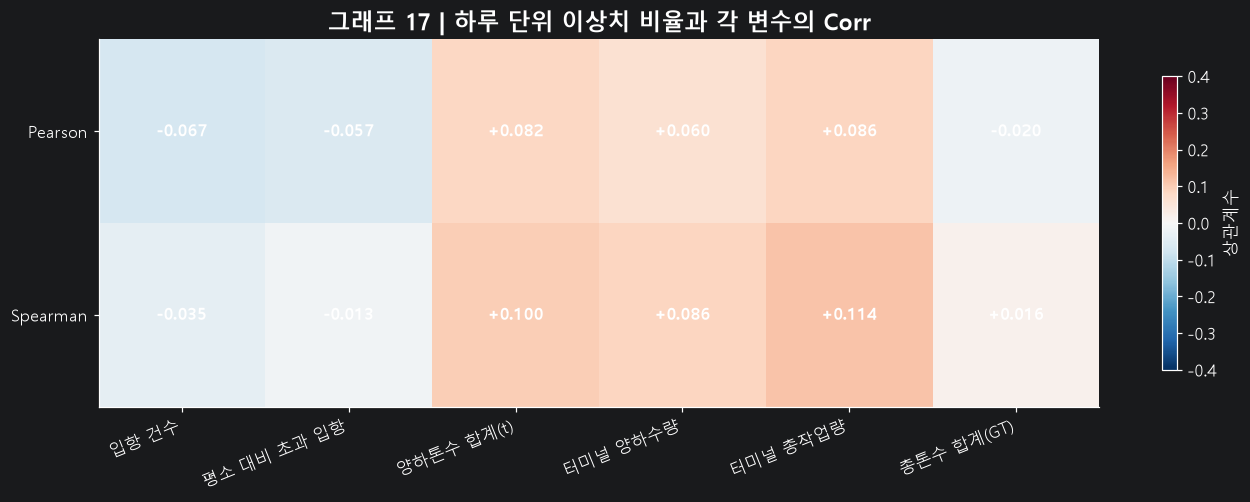

,표본일수,Pearson,Spearman
변수,,,
입항 건수,1793,-0.067,-0.035
평소 대비 초과 입항,1793,-0.057,-0.013
양하톤수 합계(t),1793,0.082,0.100
터미널 양하수량,1793,0.060,0.086
터미널 총작업량,1793,0.086,0.114
총톤수 합계(GT),1793,-0.020,0.016


In [27]:
metric_map = {
    '일일_입항건수':'입항 건수',
    '평소대비_입항초과건수':'평소 대비 초과 입항',
    '일일_양하톤수_입항선박합':'양하톤수 합계(t)',
    '일일_터미널양하수량_입항선박합':'터미널 양하수량',
    '일일_총작업량_입항선박합':'터미널 총작업량',
    '일일_총톤수_입항선박합':'총톤수 합계(GT)',
}
record = []
for col, label in metric_map.items():
    v = valid_day[[col, '장시간체류_비율']].replace([np.inf,-np.inf],np.nan).dropna()
    record.append({'변수':label,'표본일수':len(v),
                   'Pearson':v[col].corr(v['장시간체류_비율'],method='pearson'),
                   'Spearman':v[col].corr(v['장시간체류_비율'],method='spearman')})
corr_out = pd.DataFrame(record).set_index('변수')
fig,ax=plt.subplots(figsize=(12.5,4.7))
mat=corr_out[['Pearson','Spearman']].T
im=ax.imshow(mat,cmap='RdBu_r',vmin=-.4,vmax=.4,aspect='auto')
ax.set_xticks(range(len(mat.columns)),mat.columns,rotation=22,ha='right')
ax.set_yticks(range(len(mat.index)),mat.index)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j,i,f'{mat.iloc[i,j]:+.3f}',ha='center',va='center',fontsize=11,fontweight='bold')
ax.set_title('그래프 17 | 하루 단위 이상치 비율과 각 변수의 Corr')
fig.colorbar(im,ax=ax,shrink=.8,label='상관계수')
fig.tight_layout();save_show('17_이상치비율_주요변수_corr',fig)
display(corr_out.round(3))

## 그래프 18. 입항이 많은 날 장시간 체류 비율도 높아질까? — 버블 산점도

- **점 1개 = 하루**이며, 가로축은 그날 입항 건수, 세로축은 그날 입항한 선박 중 장시간 체류로 분류된 비율입니다.
- 작은 점과 큰 점의 차이는 재항시간 계산이 가능한 선박 건수입니다.
- **두꺼운 선**은 비슷한 입항량의 날을 묶어, 그 구간에서 실제 장시간 체류에 해당한 배의 비율을 계산한 결과입니다. 이 선은 산점도 점들의 단순 평균과 다릅니다.
- '입항이 많을수록 비율이 높아지는가?'를 직접 확인할 수 있습니다.

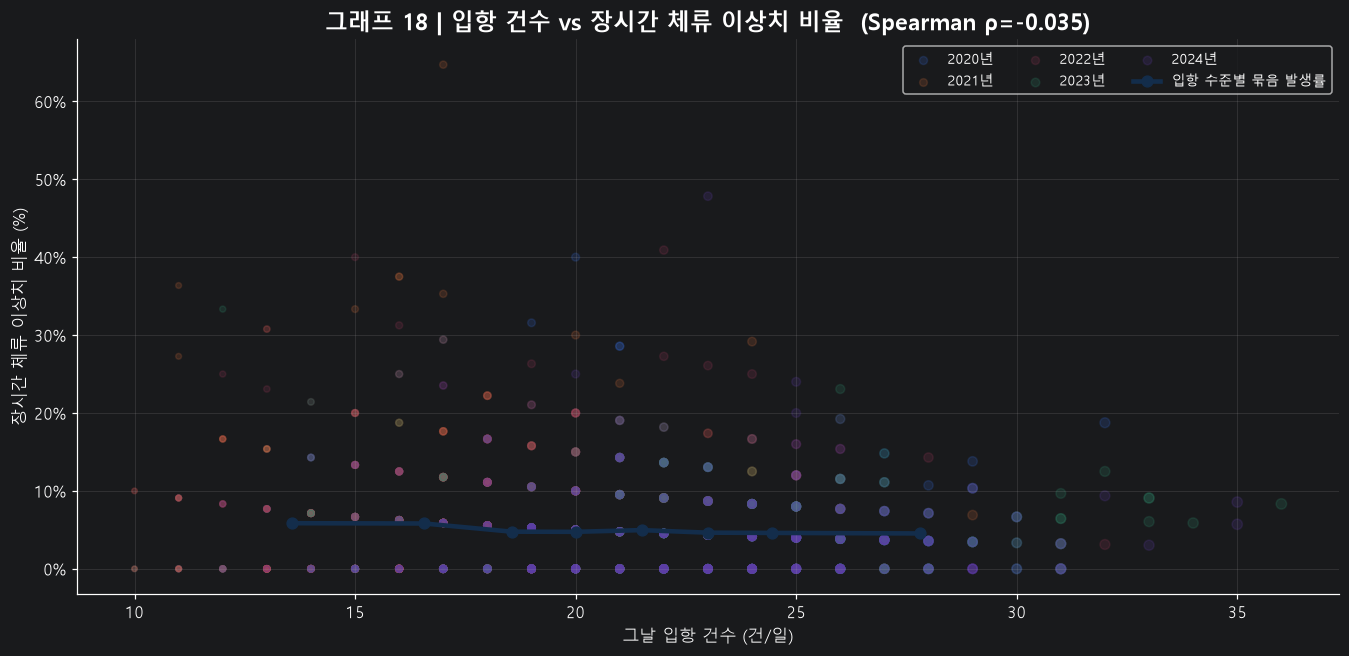

In [28]:
# 분위 그룹별 (단순 일별 비율 평균이 아니라 '전체 이상치 건수/분석 선박 건수'로 계산)
plot_day = valid_day.copy()
plot_day['입항수준구간'] = pd.qcut(plot_day['일일_입항건수'],q=8,duplicates='drop')
risk_bins = plot_day.groupby('입항수준구간',observed=True).agg(
    일수=('일일_입항건수','size'),평균입항건수=('일일_입항건수','mean'),
    이상치건수=('장시간체류_건수','sum'),분석선박=('재항분석가능건수','sum'))
risk_bins['이상치발생률'] = risk_bins['이상치건수']/risk_bins['분석선박']
fig,ax=plt.subplots(figsize=(12.4,6.1))
for year,g in plot_day.groupby('연도'):
    ax.scatter(g['일일_입항건수'],g['장시간체류_비율']*100,
               s=g['재항분석가능건수']*1.3,alpha=.18,label=f'{year}년')
ax.plot(risk_bins['평균입항건수'],risk_bins['이상치발생률']*100,
        '-o',color='#132D4B',lw=3,ms=7,label='입항 수준별 묶음 발생률')
rp=plot_day['일일_입항건수'].corr(plot_day['장시간체류_비율'],'spearman')
ax.set_title(f'그래프 18 | 입항 건수 vs 장시간 체류 이상치 비율  (Spearman ρ={rp:+.3f})')
ax.set(xlabel='그날 입항 건수 (건/일)',ylabel='장시간 체류 이상치 비율 (%)')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x,p:f'{x:.0f}%'))
ax.grid(alpha=.2);ax.legend(ncol=3,loc='upper right',fontsize=9)
fig.tight_layout();save_show('18_입항집중_이상치비율_산점도',fig)

## 그래프 19. 양하톤수·총작업량이 많은 날에 장시간 체류가 많을까? — 산점도 2개

두 지표는 **그날 입항한 선박들의 실적을 입항 날짜별로 합친 것**이지, 그날 처리된 실제 물동량이 아닙니다. 이를 혼동하면 날씨의 영향을 잘못 해석할 수 있습니다.

- 가로축이 커질수록 그 날짜에 입항한 선박들의 실적 합계가 많습니다.
- 세로축은 그날 입항한 선박 중 장시간 체류 비율입니다.
- 점들이 넓게 흩어져 있고 추세가 뚜렷하지 않으면 단순히 작업량만으로 장시간 체류를 설명하기 어렵습니다.

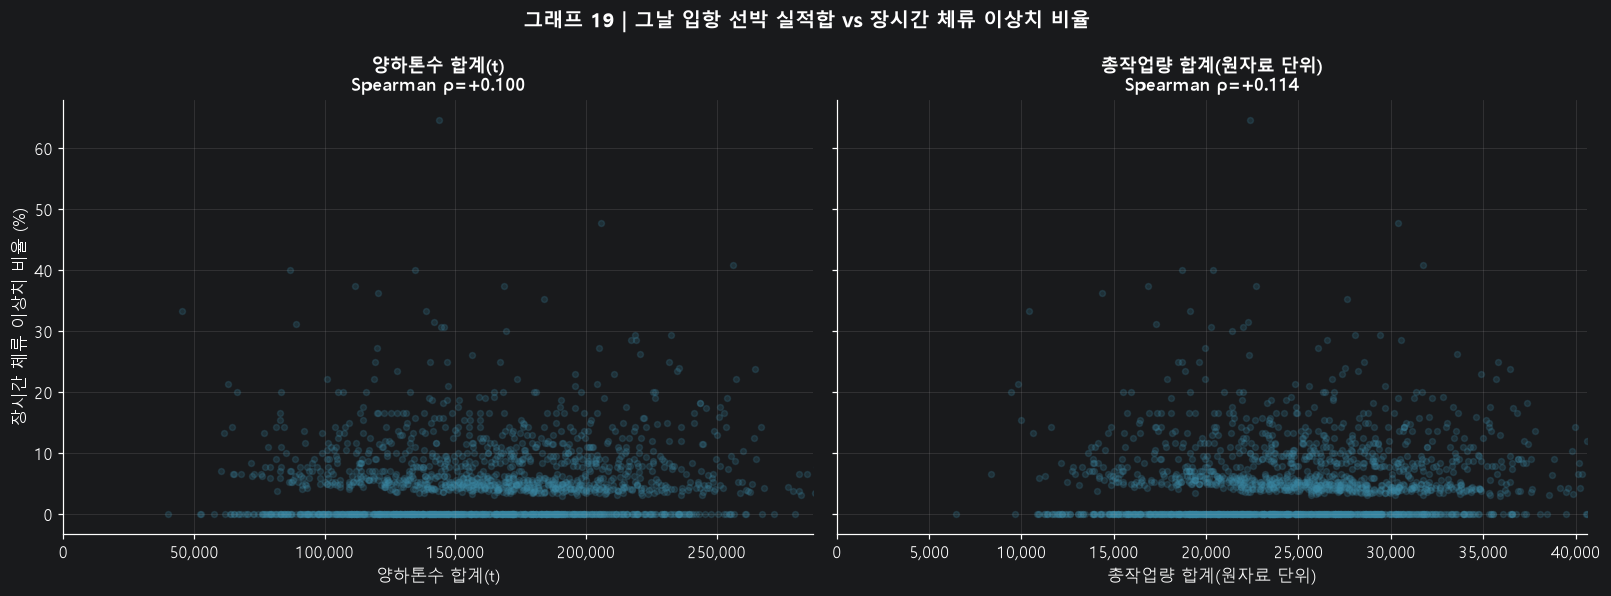

In [29]:
cols_x = [('일일_양하톤수_입항선박합','양하톤수 합계(t)'),('일일_총작업량_입항선박합','총작업량 합계(원자료 단위)')]
fig,axs=plt.subplots(1,2,figsize=(14.8,5.5),sharey=True)
for ax,(metric, lab) in zip(axs,cols_x):
    pair=valid_day[[metric,'장시간체류_비율']].dropna()
    x=pair[metric].values.astype(float); y=pair['장시간체류_비율'].values*100
    ax.scatter(x,y,c='#3C8AA6',s=15,alpha=.2)
    q95=np.nanquantile(x,.99)
    ax.set_xlim(0,q95*1.02 if q95>0 else 1)
    sp=pair[metric].corr(pair['장시간체류_비율'],method='spearman')
    ax.set_title(f'{lab}\nSpearman ρ={sp:+.3f}',fontsize=12)
    ax.set_xlabel(lab);ax.xaxis.set_major_formatter(FuncFormatter(lambda v,p:f'{v:,.0f}'))
    ax.grid(alpha=.2)
axs[0].set_ylabel('장시간 체류 이상치 비율 (%)')
fig.suptitle('그래프 19 | 그날 입항 선박 실적합 vs 장시간 체류 이상치 비율',fontweight='bold')
fig.tight_layout();save_show('19_일별양하량_작업량_이상치비율',fig)

## 그래프 20. 실제로 어느 입항 수준에서 이상치가 많이 나올까? — 구간별 발생률 + 신뢰구간

산점도는 점이 많아 눈으로 읽기 어려울 수 있습니다. 입항량이 비슷한 날짜들을 **8개 구간**으로 나누어, 각 구간의 **이상치 발생률**을 한 번에 비교합니다.

- 막대 위 수치는 `장시간 체류 이상치 건수 / 분석 선박 건수`입니다.
- 선은 불확실성의 대략적인 크기(95% Wilson 신뢰구간)를 뜻합니다. 동일한 날짜·선박이 상호 독립이라는 단순 가정에 의존하므로 실제 통계적 신뢰구간으로 단정하지 않습니다.
- 특정 구간부터 급격히 높아지는지 확인하는 용도로 사용합니다.

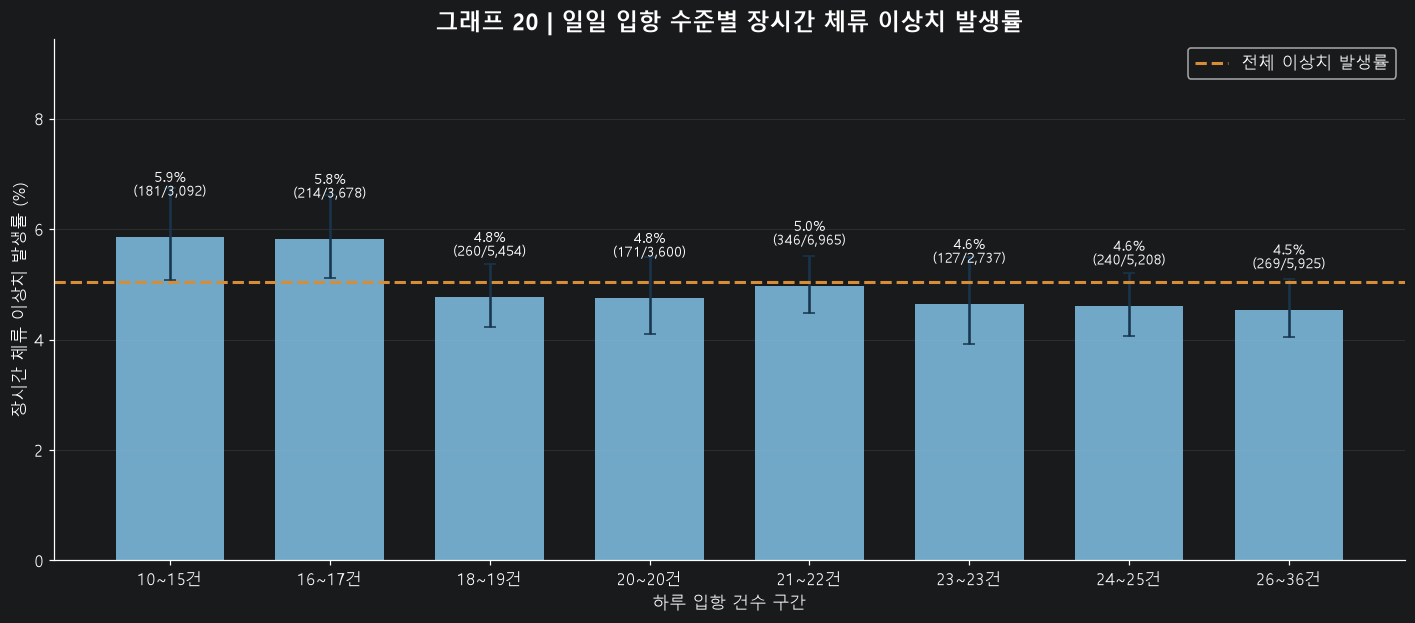

In [30]:
from math import sqrt

def wilson_ci(success, total, z=1.96):
    if total<=0:return (np.nan,np.nan)
    p=success/total; den=1+z*z/total
    center=(p+z*z/(2*total))/den
    width=z*sqrt(p*(1-p)/total+z*z/(4*total*total))/den
    return center-width,center+width

bin_df=risk_bins.reset_index().copy()
intervals=bin_df['입항수준구간']
bin_df['표시구간']=intervals.map(lambda v: f'{int(np.floor(v.left)+1)}~{int(np.floor(v.right))}건').astype(str)
interval_ci=[wilson_ci(int(k),int(n)) for k,n in zip(bin_df['이상치건수'],bin_df['분석선박'])]
lo=np.array([v[0] for v in interval_ci])*100
hi=np.array([v[1] for v in interval_ci])*100
cent=bin_df['이상치발생률'].to_numpy()*100
fig,ax=plt.subplots(figsize=(13,5.8))
xx=np.arange(len(bin_df))
ax.bar(xx,cent,color='#71A8C7',width=.68)
ax.errorbar(xx,cent,yerr=[cent-lo,hi-cent],fmt='none',color='#18354D',capsize=4,lw=1.7)
ax.axhline(outlier_ship['장시간체류_이상'].mean()*100,color=ORANGE,ls='--',lw=2,label='전체 이상치 발생률')
for x,y,k,n in zip(xx,cent,bin_df['이상치건수'],bin_df['분석선박']):
    ax.text(x,y+.7,f'{y:.1f}%\n({k:,}/{n:,})',ha='center',va='bottom',fontsize=9)
ax.set_xticks(xx,bin_df['표시구간'])
ax.set(xlabel='하루 입항 건수 구간',ylabel='장시간 체류 이상치 발생률 (%)')
ax.set_title('그래프 20 | 일일 입항 수준별 장시간 체류 이상치 발생률')
ax.legend();ax.grid(axis='y',alpha=.18);ax.set_ylim(0,max(cent.max(),hi.max())*1.4)
fig.tight_layout();save_show('20_일일입항구간별_이상치발생률',fig)

## 그래프 21. 당일보다 전날·이틀 전 입항량이 더 관련이 클까? — 시차 Corr

이번에는 **이상치가 발생한 배의 입항일을 기준**으로, 그 날짜와 그 전후 입항 건수를 비교합니다.

- `-2`: 분석 대상 날짜보다 **이틀 뒤**의 입항 건수
- `0`: **당일** 입항 건수
- `+2`: **이틀 전**의 입항 건수

양수 쪽에서 더 높은 상관계수가 나타나면 전날·이틀 전의 입항량이 단서가 될 수 있지만, 날씨·요일·선박 구성 등을 통제하기 전에는 원인이라고 말할 수 없습니다.

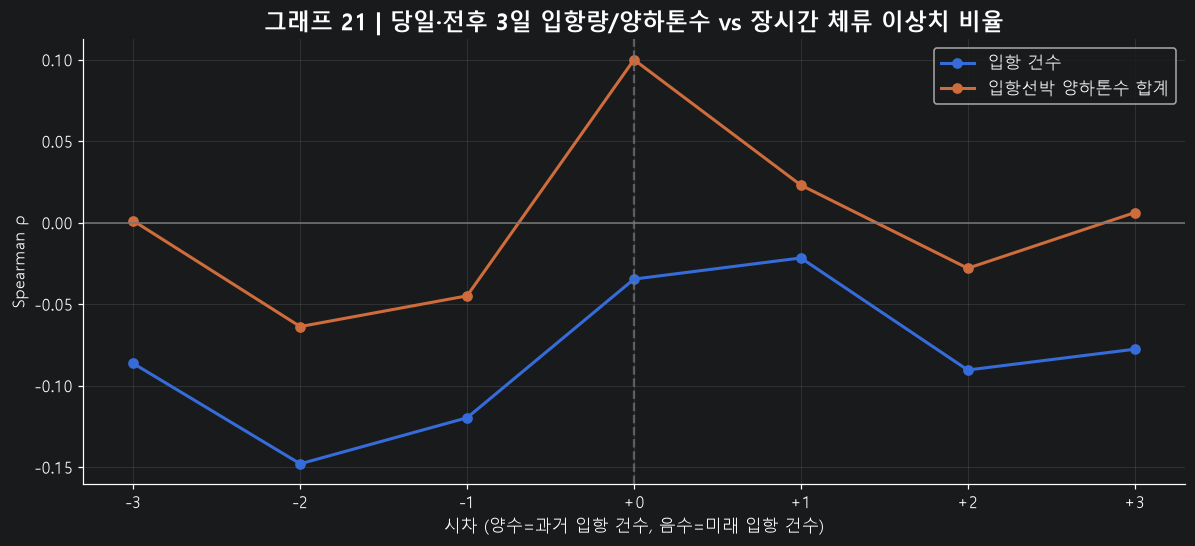

In [31]:
lags=list(range(-3,4))
lag_res=[]
for lag in lags:
    # shift(+2) = 해당 날짜 기준 '이틀 전'의 입항 건수
    for metric,lbl in [('일일_입항건수','입항 건수'),('일일_양하톤수_입항선박합','입항선박 양하톤수 합계')]:
        dat=pd.DataFrame({'x':outlier_day[metric].shift(lag),'y':outlier_day['장시간체류_비율'],
                          'n':outlier_day['재항분석가능건수']})
        dat=dat.loc[dat['n']>=MIN_SHIPS_PER_DAY].dropna()
        lag_res.append({'일차이':lag,'지표':lbl,'Spearman':dat['x'].corr(dat['y'],'spearman'),'일수':len(dat)})
lag_table=pd.DataFrame(lag_res)
fig,ax=plt.subplots(figsize=(11,5.1))
for lbl,g in lag_table.groupby('지표',sort=False):
    ax.plot(g['일차이'],g['Spearman'],marker='o',lw=2,label=lbl)
ax.axvline(0,color='#777',ls='--',alpha=.7)
ax.axhline(0,color='#777',lw=1)
ax.set_xticks(lags,[f'{l:+d}' for l in lags])
ax.set(xlabel='시차 (양수=과거 입항 건수, 음수=미래 입항 건수)',ylabel='Spearman ρ')
ax.set_title('그래프 21 | 당일·전후 3일 입항량/양하톤수 vs 장시간 체류 이상치 비율')
ax.legend();ax.grid(alpha=.2)
fig.tight_layout();save_show('21_전후입항량_이상치비율_시차_corr',fig)

## 그래프 22. 시각 오류 의심 이상치와 장시간 체류 이상치는 같은가?

'이상치'라는 단어가 같아도 **이상한 데이터**와 **운영상 장시간 체류**는 다릅니다. 입항량이 비슷한 날짜들을 묶어 두 이상치의 비율을 나란히 확인합니다.

- **장시간 체류:** 재항시간 상위 5%를 넘는 선박 비율
- **시각 오류 의심:** 원본의 `터미널접안_시간관계검증 == '이상'` 비율
- 시각 오류 의심 비율이 높다고 반드시 기상 지연이 컸다는 뜻은 아닙니다.

In [32]:
if '시각오류의심비율' in valid_day.columns:
    cmp = valid_day.copy()
    cmp['입항구간'] = pd.qcut(cmp['일일_입항건수'],q=8,duplicates='drop')
    tmp=cmp.groupby('입항구간',observed=True).agg(
        장기건수=('장시간체류_건수','sum'),장기모수=('재항분석가능건수','sum'),
        시각의심건수=('시각오류의심건수','sum'),시각모수=('시각검증모수','sum'))
    tmp['장기비율']=tmp['장기건수']/tmp['장기모수']*100
    tmp['시각비율']=tmp['시각의심건수']/tmp['시각모수']*100
    lab=[f'{int(np.floor(iv.left)+1)}~{int(np.floor(iv.right))}' for iv in tmp.index]
    xx=np.arange(len(tmp));fig,ax=plt.subplots(figsize=(12.3,5.2));w=.38
    ax.bar(xx-w/2,tmp['장기비율'],width=w,label='장시간 체류 후보',color=BLUE)
    ax.bar(xx+w/2,tmp['시각비율'],width=w,label='접안 시각 관계 이상',color=ORANGE)
    ax.set_xticks(xx,lab);ax.set_xlabel('하루 입항 건수 구간(건)');ax.set_ylabel('해당 유형 이상치 비율 (%)')
    ax.set_title('그래프 22 | 운영상 장시간 체류 vs 시각 관계 오류 의심 (서로 다른 정의)')
    ax.legend();ax.grid(axis='y',alpha=.18)
    fig.tight_layout();save_show('22_장시간체류_시각이상_종류비교',fig)
else:
    print('원본에 시각 관계 검증 열이 없어 이 비교를 생략합니다.')

원본에 시각 관계 검증 열이 없어 이 비교를 생략합니다.


## 그래프 23. 터미널마다 입항 집중과 장시간 체류의 관계가 다를까?

부산항 전체에서는 상관계수가 작더라도 특정 터미널에서는 다른 모습을 보일 수 있습니다. 터미널별 **하루 입항 선박 3건 이상**인 날만 사용합니다. 표본 일수가 너무 적은 터미널은 제외합니다.

막대가 길다고 곧바로 터미널의 성능이 좋거나 나쁘다고 해석하면 안 됩니다. 선박 구성·작업종류·연도 차이가 남아 있습니다.

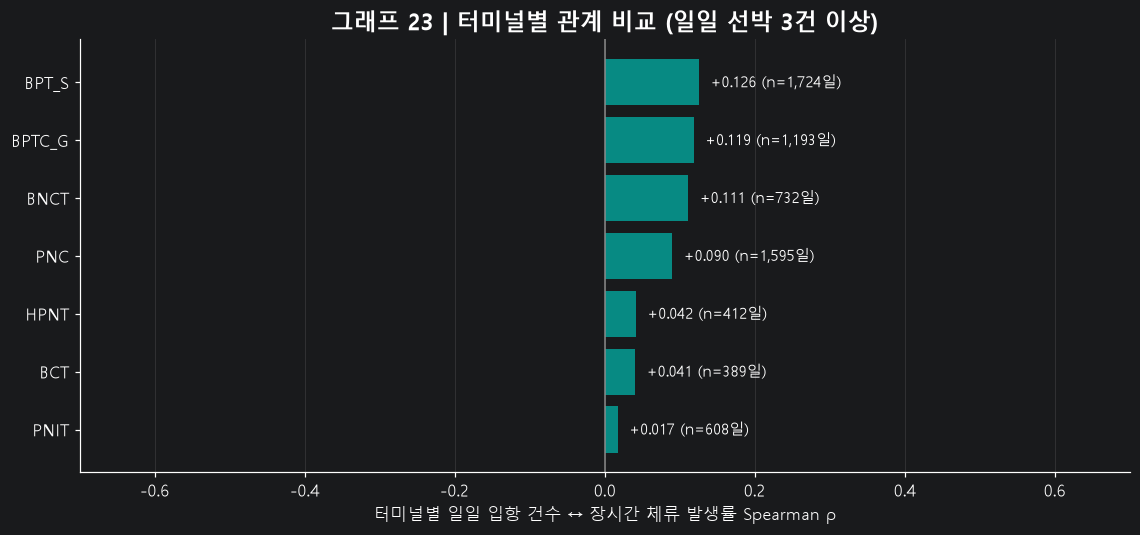

,터미널,비교한날,Spearman
6,PNIT,608,0.017
0,BCT,389,0.041
4,HPNT,412,0.042
5,PNC,1595,0.090
1,BNCT,732,0.111
2,BPTC_G,1193,0.119
3,BPT_S,1724,0.126


In [33]:
term_ship = outlier_ship.groupby(['터미널','입항일'])['장시간체류_이상'].agg(
    분석건수='size',이상건수='sum').reset_index()
term_ship['이상비율']=term_ship['이상건수']/term_ship['분석건수']
term_ship = term_ship.loc[term_ship['분석건수']>=3].copy()
term_res=[]
for terminal,sub in term_ship.groupby('터미널'):
    if len(sub)<30:continue
    r=sub['분석건수'].corr(sub['이상비율'],'spearman')
    term_res.append((terminal,len(sub),r))
term_res=pd.DataFrame(term_res,columns=['터미널','비교한날','Spearman']).sort_values('Spearman')
fig,ax=plt.subplots(figsize=(10.5,5.0))
ax.barh(term_res['터미널'],term_res['Spearman'],color=[TEAL if v>=0 else ORANGE for v in term_res['Spearman']])
ax.axvline(0,color='#888',lw=1)
for i,(_,r) in enumerate(term_res.iterrows()):
    ax.text(r['Spearman']+(0.015 if r['Spearman']>=0 else -0.015),i,
            f"{r['Spearman']:+.3f} (n={int(r['비교한날']):,}일)",
            va='center',ha=('left' if r['Spearman']>=0 else 'right'),fontsize=10)
ax.set_xlim(-.7,.7);ax.set_xlabel('터미널별 일일 입항 건수 ↔ 장시간 체류 발생률 Spearman ρ')
ax.set_title('그래프 23 | 터미널별 관계 비교 (일일 선박 3건 이상)')
ax.grid(axis='x',alpha=.2)
fig.tight_layout();save_show('23_터미널별_입항건수_장시간체류_corr',fig)
display(term_res.round(3))

## 결과 정리: 어떻게 해석해야 할까?

1. **상관계수가 낮으면** 전체 기간에서 *단순하고 단조로운 관계*가 약하다는 뜻입니다. 특정 입항량을 넘어선 순간 급증하는 **임계값·비선형 패턴**이 있을 수 있으므로 그래프 20도 같이 보아야 합니다.
2. **장시간 체류 건수보다 발생률**을 사용해야 날짜마다 다른 입항 규모를 비교할 수 있습니다.
3. **양하톤수·총작업량은 선박의 입항일에 연결한 총실적**입니다. 해당 날짜에 실제로 처리한 작업량이 아닙니다. 원인이 아니라 결과가 섞인 수치일 수 있습니다.
4. **시간차 그래프**는 날씨 데이터와 결합하기 위한 사전 탐색입니다. 상관이 높아도 날씨가 원인이라는 증거가 되지는 않습니다.
5. **주의: 기간별·터미널별 선박 구성이 달라질 수 있습니다.** 해석 단계에서는 최소한 연도·월·요일·터미널·선박 크기 차이를 고려한 로지스틱 회귀나 군집 기반 통계도 검토하는 것이 좋습니다.
6. **정의의 민감도 확인**: 상위 5% 대신 10%·2.5%, 30일 초과 초장기 기록 별도 검토 등의 설정을 바꿔도 같은 패턴이 나오는지 비교하세요. 원인을 확인하지 않은 극단값을 무조건 삭제하지 않습니다.

### 날씨와 결합할 때 추천할 첫 실험
- **전날 유의파고/풍속**, **당일 풍속**, **당일 입항 초과건수**와 **장시간 체류 발생 여부**의 관계를 터미널·총톤수·연도 차이를 보정하여 비교합니다.
- 날씨가 나쁜 날 다음날이 더 중요한지 탐색할 때는 **전날 입항·작업량**을 별도로 사용합니다.
- '접안 시각 오류 의심'은 분석에서 별도 데이터 품질 레이어로 둡니다.

In [34]:
# CSV 출력: 날짜별 표 + 선박별 장시간 체류 후보 + 상관계수 + 발생률 구간
outlier_day.reset_index().to_csv(OUTPUT_DIR/'이상치분석_일별지표.csv',index=False,encoding='utf-8-sig')
selected=['선박키','입항_dt','출항_dt','입항일','터미널','총톤수_GT','크기_광역',
          '재항시간_h','적용경계시간','장시간체류_이상','그룹건수']
selected=[x for x in selected if x in outlier_ship.columns]
outlier_ship[selected].to_csv(OUTPUT_DIR/'이상치분석_선박별_재항시간_플래그.csv',index=False,encoding='utf-8-sig')
corr_out.reset_index().to_csv(OUTPUT_DIR/'이상치분석_corr_결과.csv',index=False,encoding='utf-8-sig')
bin_df.to_csv(OUTPUT_DIR/'이상치분석_입항구간별_발생률.csv',index=False,encoding='utf-8-sig')
lag_table.to_csv(OUTPUT_DIR/'이상치분석_시차상관계수.csv',index=False,encoding='utf-8-sig')
term_res.to_csv(OUTPUT_DIR/'이상치분석_터미널별상관계수.csv',index=False,encoding='utf-8-sig')
print('저장 위치:',OUTPUT_DIR)

저장 위치: C:\work\Port_Cast_Final\1.Rawdata_EDA\Output\부산항_기초분석_산출물
